# Evidencia experimental · Voz del Cliente más allá del NPS

**Equipo 14 · Artículo de difusión · 8 de noviembre de 2026**

Esta libreta acompaña al artículo y reúne la evidencia para consultar sus figuras, tablas y resultados. Sigue el recorrido **datos → relevancia → sentimiento histórico → agrupamiento e interpretación → operación**.

Se ejecuta con datos de apoyo incluidos en `../soporte-articulo-14/sources/evidencia-articulo-14/`. No descarga modelos, no necesita credenciales, no accede a `data/` y no realiza llamadas a un LLM. Recalcula estadísticas sobre predicciones y asignaciones ya guardadas. **No vuelve a entrenar Robertuito, SVM, UMAP ni HDBSCAN.**

Las métricas de Robertuito pertenecen a una evaluación histórica diferente de nuestra muestra de 1.000 reseñas. Los nombres del LLM y las revisiones humanas se conservan como evidencia registrada, no se vuelven a generar ni se consideran automáticamente correctos.

## Cómo consultarla

Puede leerse con las salidas guardadas, o ejecutarse de principio a fin con Jupyter. Dependencias: `numpy`, `pandas`, `matplotlib`, `scikit-learn` e `IPython`. La última celda produce un recibo con las verificaciones. Las salidas nuevas quedan en `../soporte-articulo-14/exports/evidencia-articulo-14/`, separadas de las fuentes.

1. Integridad e índice de figuras.
2. Corpus y muestra — figura 1, tabla 1.
3. Metodología documentada — figuras 2–4, tabla 2 y ejemplos de 3.6.
4. Relevancia — figura 5, tabla 3.
5. Transfer learning — figura 6.
6. Agrupamiento, interpretación y sentimiento — figura 7, anexo A.
7. Implementación y costos — figuras 8–9, tablas 4–6, anexo B.
8. Auditoría final y procedencia.


In [1]:
from pathlib import Path
from datetime import datetime, timezone
from decimal import Decimal
import hashlib, json, re, html, textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image, HTML
from sklearn.metrics import accuracy_score, balanced_accuracy_score, precision_recall_fscore_support, confusion_matrix

# Funciona desde la carpeta de esta libreta o desde la raíz del repositorio.
candidates=[Path.cwd(), *Path.cwd().parents]
ROOT=next(q for p in candidates for q in [p/'soporte-articulo-14',p/'reports/soporte-articulo-14'] if (q/'sources/evidencia-articulo-14/manifest.json').is_file())
INPUT=ROOT/'sources/evidencia-articulo-14'
OUT=ROOT/'exports/evidencia-articulo-14'/datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
OUT.mkdir(parents=True,exist_ok=False)
digest=lambda p:hashlib.sha256(p.read_bytes()).hexdigest()
assert digest(INPUT/'manifest.json')=='a4d18d096093f62cea172a5c3dc8055093785bf2af098cb7950399e6caa17062'
manifest=json.loads((INPUT/'manifest.json').read_text())
checks=[]
def check(name,condition):
    if not bool(condition): raise AssertionError(name)
    checks.append(name)
for path,expected in manifest['files'].items():
    check('Integridad: '+path,digest(INPUT/path)==expected)
read=lambda name:pd.read_csv(INPUT/name)
load=lambda name:json.loads((INPUT/name).read_text())
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,'axes.spines.top':False,'axes.spines.right':False})
BLUE='#306B8D';ORANGE='#DD7848'
LABELS=['negative','neutral','positive'];COLORS=['#BC5051','#A8AFB8','#468C73']
fig_index=load('indice-figuras.json'); report_tables=load('tablas-articulo.json')
def show_figure(label):
    item=next(x for x in fig_index if x['label']==label)
    display(Markdown(f"**Figura {item['number']} · {item['kind']}** — {item['caption']}"))
    display(Image(filename=str(INPUT/item['image']),width=1000))
def show_table(label):
    item=next(x for x in report_tables if x['label']==label)
    display(Markdown(item['caption']))
    display(pd.DataFrame(item['rows'],columns=item['headers']))
def save_figure(fig,name):
    fig.savefig(OUT/(name+'.png'),dpi=150,bbox_inches='tight',facecolor='white')
    fig.savefig(OUT/(name+'.pdf'),bbox_inches='tight',facecolor='white')
    plt.close(fig)
print(f"{len(manifest['files'])} archivos verificados. Sin ajustes ni solicitudes al proveedor.")
display(pd.DataFrame(fig_index)[['number','label','kind']])


46 archivos verificados. Sin ajustes ni solicitudes al proveedor.


,number,label,kind
0,1,fig:corpus-mensual,calculada
1,2,fig:propuesta-dos-modelos,documental
2,3,fig:umap-vecindades,documental
3,4,fig:hdbscan-base-alternativa,calculada
4,5,fig:resultados-relevancia-comparada,calculada
5,6,fig:resultados-sentimiento-historico,calculada
6,7,fig:resultados-distribucion-combinada,calculada
7,8,fig:arquitectura-operacion-propuesta,documental
8,9,fig:ciclo-react-consulta,documental
9,A.1,fig:anexo-topicos-sentimiento,calculada


## 1. Datos y selección de la muestra

Recalculamos la cobertura desde un extracto por registro que conserva identificador, fecha y plataforma, sin necesitar los textos de todo el corpus. Los registros no equivalen a personas. Septiembre de 2026 es parcial.

La ventana de julio–agosto contiene 15.626 registros. Antes de muestrear se excluyeron 29 registros por solapamiento con las anotaciones del filtro. La distribución estratificada y la semilla están documentadas en el protocolo guardado. Aquí verificamos los conteos y la composición, sin volver a sortear la muestra.

,eligible,month,platform,selected
0,390,2026-07,app_store,25
1,383,2026-08,app_store,24
2,6130,2026-07,google_play,393
3,7535,2026-08,google_play,483
4,494,2026-07,x,32
5,498,2026-08,x,32
6,73,2026-07,youtube,5
7,94,2026-08,youtube,6


**Figura 1 · calculada** — Registros por mes y fuente. El volumen describe el corpus recolectado, no el número de usuarios ni la frecuencia real de problemas.

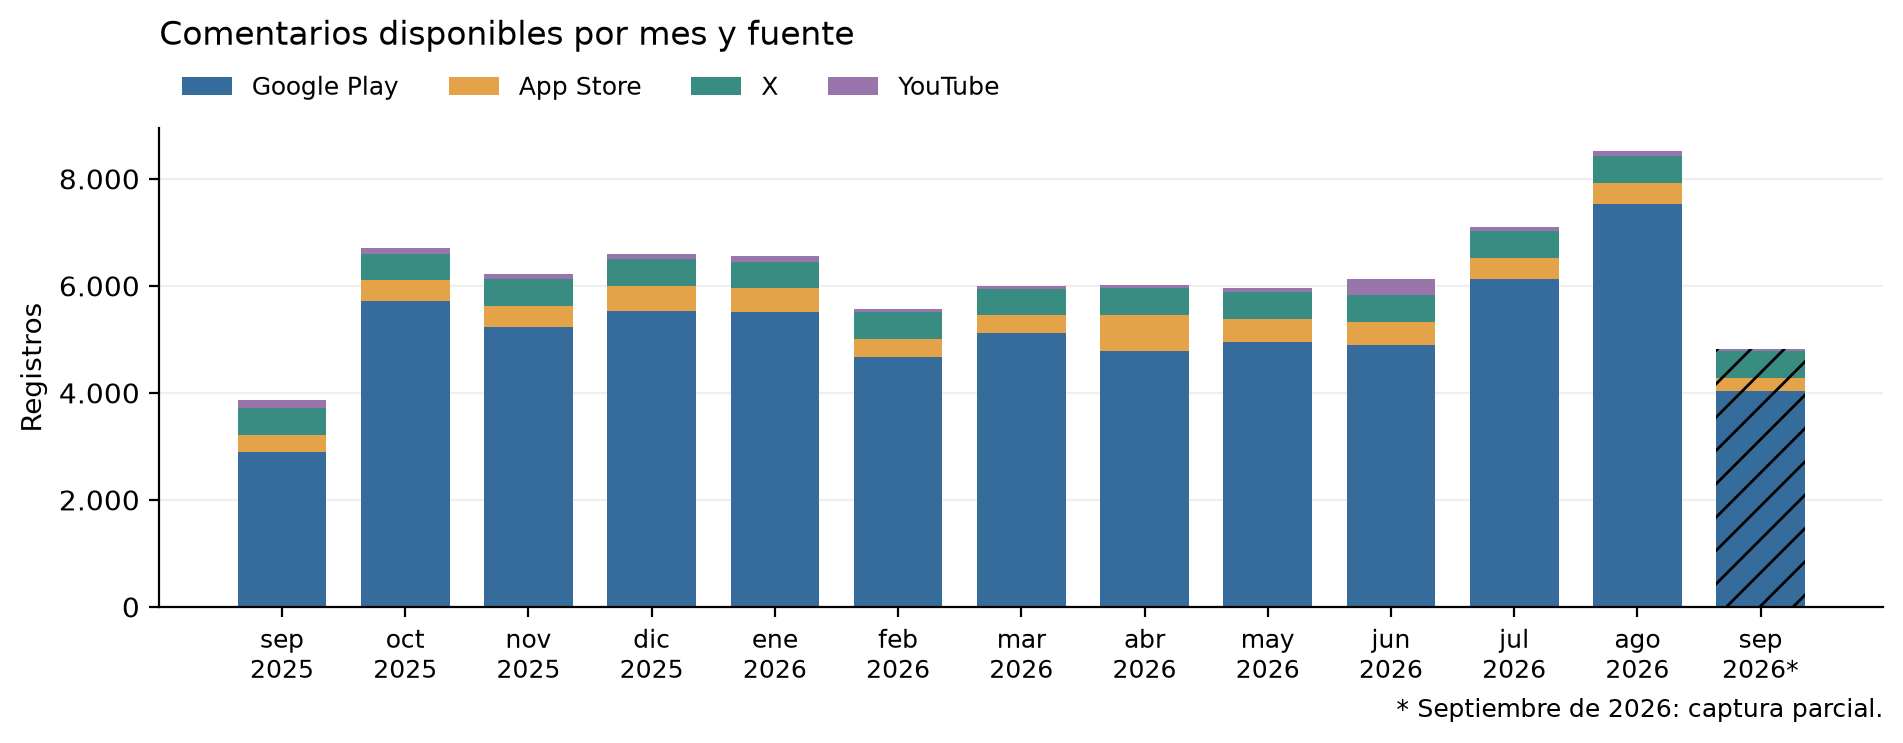

Muestra común y registros retenidos por el filtro de la alternativa. Las exclusiones son predicciones, no decisiones humanas.

,Plataforma,Julio,Agosto,Inicial,Retenidos
0,App Store,25,24,49,49
1,Google Play,393,483,876,876
2,X,32,32,64,62
3,YouTube,5,6,11,0
4,Total,455,545,1.000,987


In [2]:
corpus=read('corpus-fechas.csv.gz')
check('Corpus: 80.079 IDs únicos',len(corpus)==80079 and corpus.record_id.is_unique)
dates=pd.to_datetime(corpus.record_date,format='mixed',utc=True,errors='raise')
platforms=['google_play','app_store','x','youtube']
monthly=pd.crosstab(dates.dt.strftime('%Y-%m'),corpus.platform).reindex(columns=platforms)
expected=read('corpus-registros-por-mes-y-fuente.csv').set_index('month')[platforms]
check('Todos los conteos mensuales coinciden',np.array_equal(monthly.values,expected.values) and list(monthly.index)==list(expected.index))
check('Julio–agosto: 15.626 registros',monthly.loc[['2026-07','2026-08']].to_numpy().sum()==15626)
sampling=read('muestra-plataforma-mes.csv');protocol=load('protocolo-extracto.json')
check('Muestra estratificada: 1.000',sampling.selected.sum()==1000)
check('Elegibles después de excluir solapamientos',sampling.eligible.sum()==15626-29)
check('Solapamientos documentados',protocol['sampling']['annotation_overlap_excluded']==29)
display(sampling);monthly.to_csv(OUT/'corpus-mensual-recalculado.csv')
fig,ax=plt.subplots(figsize=(9,3.5),layout='constrained')
monthly.rename(columns=dict(zip(platforms,['Google Play','App Store','X','YouTube']))).plot.bar(stacked=True,ax=ax,color=['#356C9B','#E4A349','#398C81','#9875AB'],rot=45)
ax.set(ylabel='Registros',xlabel='Mes',title='Cobertura por mes y fuente · septiembre 2026 parcial')
save_figure(fig,'figura-1-recalculada')
show_figure('fig:corpus-mensual');show_table('tab:muestra')


## 2. Configuración y ejemplos de metodología

Las figuras 2 y 3 son **esquemas explicativos**, no mediciones. Se conservan tal como aparecen en el artículo. La configuración temática se documenta en el protocolo de la comparación. La figura 4 se puede reconstruir desde las coordenadas guardadas de una proyección visual común. Esas dos coordenadas sirven para visualizar, mientras el agrupamiento utiliza la reducción a cinco dimensiones.

Las librerías y el prototipo se documentan en las fuentes del cierre. La ejecución de esta libreta no prueba por sí sola que el software cumpla todas las propiedades descritas en los diagramas.

**Figura 2 · documental** — Modelo base y alternativo. Las etapas compartidas conservan su configuración; cada sistema ajusta sus grupos sobre las reseñas que recibe. Ilustración elaborada con asistencia de IA.

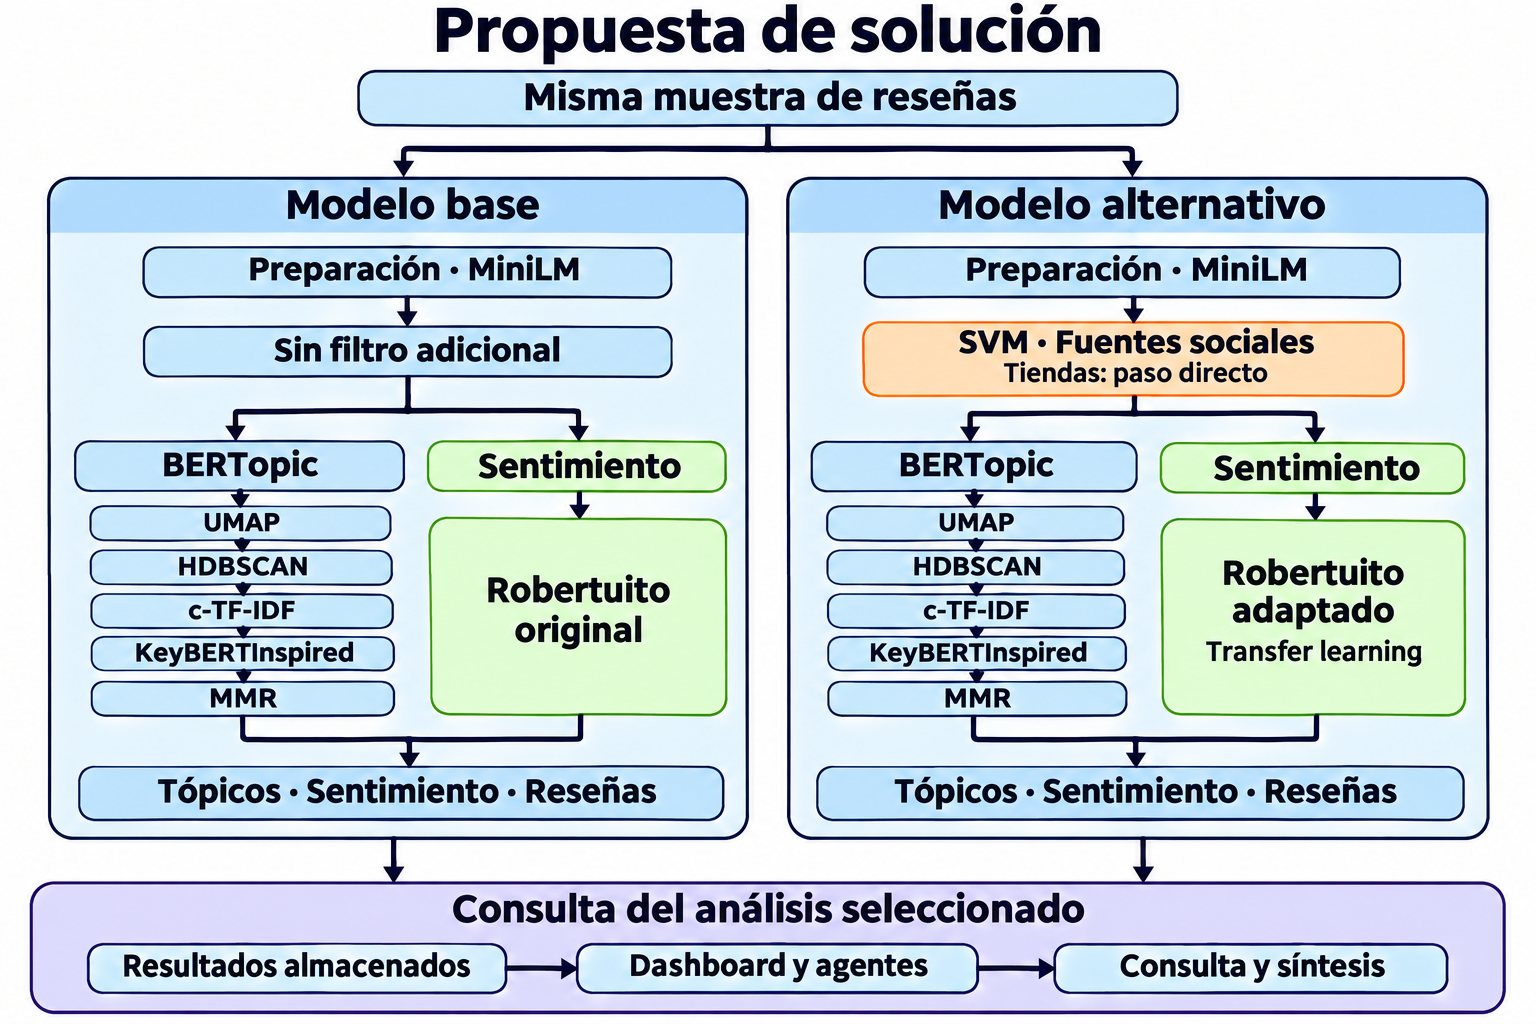

**Figura 3 · documental** — Esquema conceptual de UMAP: se conservan las filas y se calculan cinco coordenadas por reseña a partir de las vecindades. Las celdas y conexiones son ilustrativas.

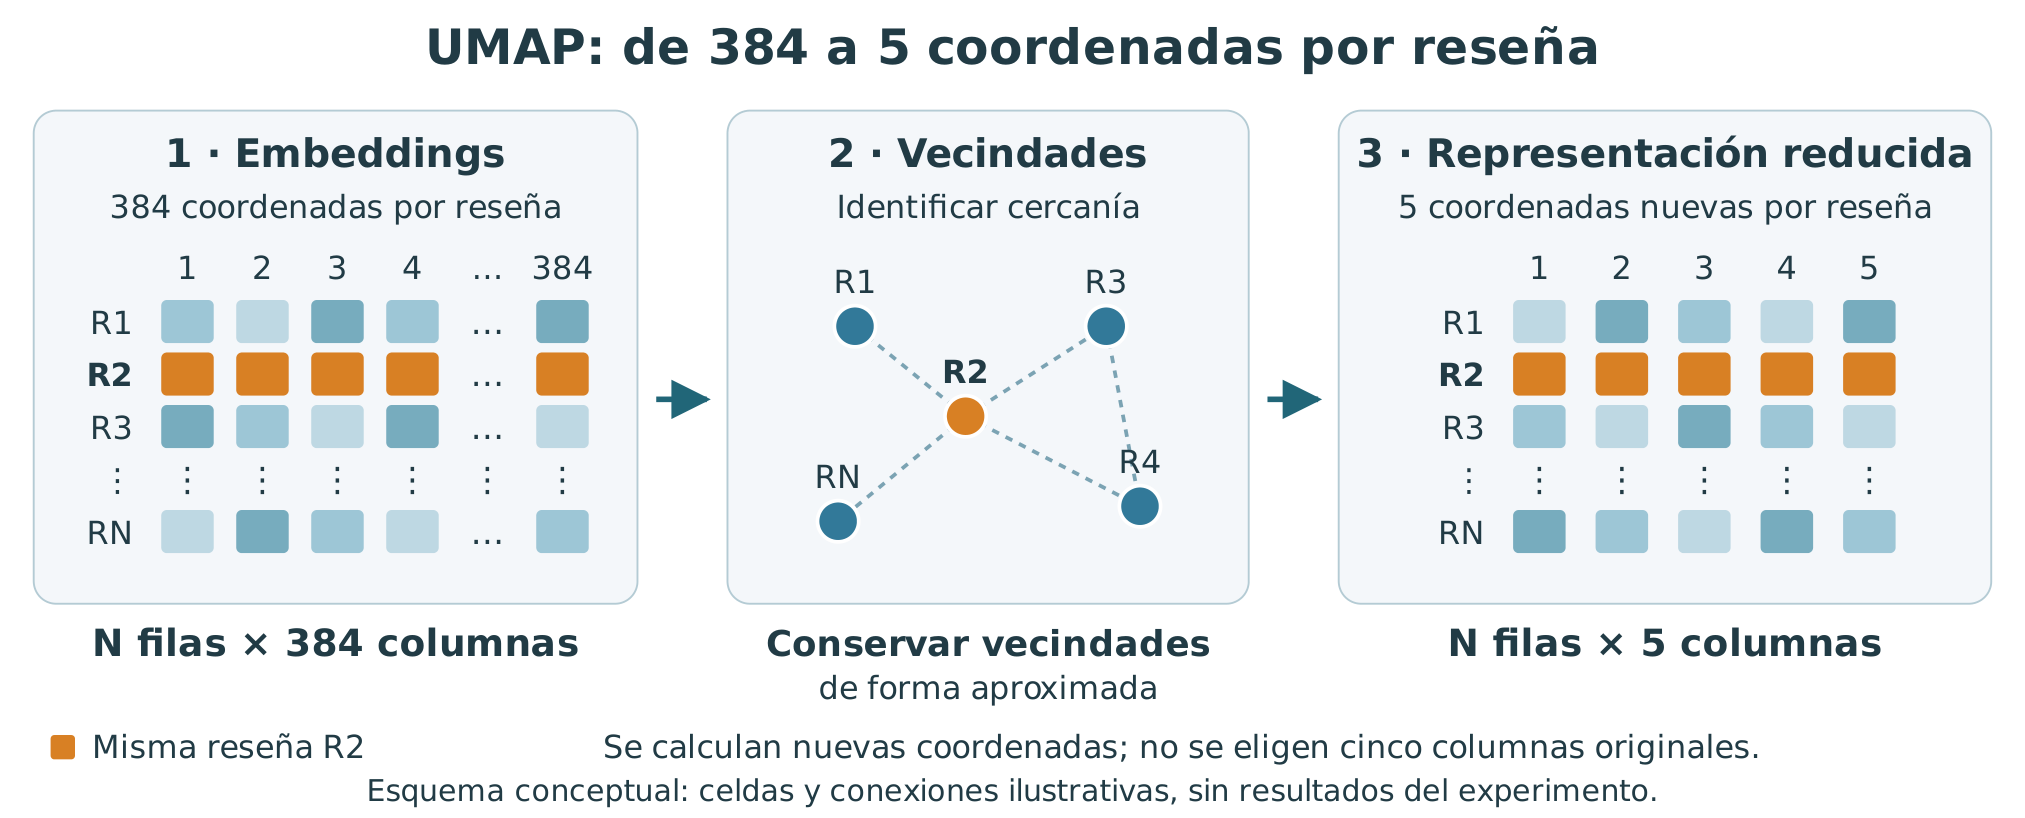

,clustering.cluster_selection_method,clustering.metric,clustering.min_cluster_size,clustering.min_samples,reduction.metric,reduction.min_dist,reduction.n_components,reduction.n_neighbors,reduction.random_state,selection.kind,selection.seed,selection.size,topics.backend
0,eom,euclidean,10,3,cosine,0.0,5,15,42,full,None,None,bertopic


Configuración temática común a los dos sistemas. La proyección visual de dos dimensiones se calcula por separado.

,Etapa,Parámetros fijados,Papel
0,UMAP,`n_components=5`; `n_neighbors=15`; `metric=co...,Define la representación y sus vecindades.
1,HDBSCAN,`min_cluster_size=10`; `min_samples=3`; `metri...,Estima densidad y selecciona grupos de la jera...


Ejemplo ilustrativo del efecto de la raíz cuadrada sobre TF.

,Término,Frecuencia normalizada,Con raíz
0,aplicación,"25/100 = 0,25","0,50"
1,transferencia,"4/100 = 0,04","0,20"


,Campo,Respuesta guardada
0,name,Problemas de congelación y rendimiento de la a...
1,topic_description,Los usuarios reportan que la aplicación se con...
2,proposed_feature,Mejorar la estabilidad de la aplicación para e...
3,assessment,single_feature
4,supporting_evidence,"[E1, E2, E3, E4, E5, E6]"


In [3]:
show_figure('fig:propuesta-dos-modelos');show_figure('fig:umap-vecindades')
display(pd.json_normalize(protocol['grouping']))
check('UMAP de agrupamiento: 5 dimensiones',protocol['grouping']['reduction']['n_components']==5)
check('HDBSCAN compartido: eom, mínimo 10',protocol['grouping']['clustering']['cluster_selection_method']=='eom' and protocol['grouping']['clustering']['min_cluster_size']==10)
check('Todos los parámetros UMAP de la tabla 2',protocol['grouping']['reduction']=={'metric':'cosine','min_dist':0.0,'n_components':5,'n_neighbors':15,'random_state':42})
check('Todos los parámetros HDBSCAN de la tabla 2',protocol['grouping']['clustering']=={'cluster_selection_method':'eom','metric':'euclidean','min_cluster_size':10,'min_samples':3})
show_table('tab:configuracion')
# El ejemplo c-TF-IDF es didáctico, no una estimación de pesos del experimento.
frequencies=np.array([25,4])/100
check('Raíz de TF: 0,50 y 0,20',np.allclose(np.sqrt(frequencies),[.5,.2]))
check('Relación de frecuencias: 6,25 a 2,5',np.isclose(frequencies[0]/frequencies[1],6.25) and np.isclose(np.sqrt(frequencies[0])/np.sqrt(frequencies[1]),2.5))
show_table('tab:ejemplo-raiz-ctfidf')
example=load('ejemplo-llm.json')
display(pd.DataFrame(example['response_fields_verbatim'].items(),columns=['Campo','Respuesta guardada']))
check('Ejemplo LLM registrado: tópico 18 alternativo',example['topic_id']==18 and example['system']=='alternative')


## 3. Filtro de relevancia: métricas y errores

Calculamos las métricas directamente desde las 160 predicciones fuera de muestra de cada clasificador. Cada registro tiene una predicción de su partición de validación. Ambos clasificadores usaron los mismos objetivos y particiones. Las 45 anotaciones inciertas quedaron fuera del entrenamiento, no fueron etiquetadas como irrelevantes.

Esta validación también se utilizó para elegir el filtro. **No existe una prueba independiente posterior a la selección.** El control por plataforma sirve para detectar cuánto puede explicar la composición de la muestra. El SVM admitió un irrelevante menos que logística, pero perdió tres relevantes adicionales. No fue el mejor modelo en F1.

In [4]:
svm=read('relevancia-svm.csv');lr=read('relevancia-logreg.csv');receipt=load('relevancia-recibo.json')
check('Mismas filas, etiquetas y cinco particiones',len(svm)==160 and svm.record_id.is_unique and svm[['record_id','platform','fold','target']].equals(lr[['record_id','platform','fold','target']]) and svm.fold.nunique()==5)
check('205 anotaciones menos 45 inciertas',receipt['svm']['rows_annotated']==205 and receipt['svm']['uncertain_excluded']==45 and receipt['svm']['rows_trained']==160)
metrics=[];matrices={}
for name,key,pred in [('SVM','svm',svm.prediction),('Logística','logistic_regression',lr.prediction),('Control plataforma','platform_control',svm.platform_control)]:
    precision,recall,f1,_=precision_recall_fscore_support(svm.target,pred,average='binary',zero_division=0)
    cm=confusion_matrix(svm.target,pred,labels=[0,1]);matrices[name]=cm
    row=dict(model=name,accuracy=accuracy_score(svm.target,pred),balanced_accuracy=balanced_accuracy_score(svm.target,pred),precision_relevant=precision,recall_relevant=recall,f1_relevant=f1,irrelevant_passed=int(cm[0,1]),relevant_lost=int(cm[1,0]))
    for metric in ['accuracy','balanced_accuracy','precision_relevant','recall_relevant','f1_relevant']:
        check(name+' coincide: '+metric,np.isclose(row[metric],receipt[key][metric]))
    metrics.append(row)
relevance=pd.DataFrame(metrics);display(relevance.round(6));relevance.to_csv(OUT/'relevancia-recalculada.csv',index=False)
check('SVM: 7 falsos positivos y 7 negativos',matrices['SVM'][0,1]==7 and matrices['SVM'][1,0]==7)
check('Logística: 8 falsos positivos y 4 negativos',matrices['Logística'][0,1]==8 and matrices['Logística'][1,0]==4)


,model,accuracy,balanced_accuracy,precision_relevant,recall_relevant,f1_relevant,irrelevant_passed,relevant_lost
0,SVM,0.91250,0.908854,0.927083,0.927083,0.927083,7,7
1,Logística,0.92500,0.916667,0.920000,0.958333,0.938776,8,4
2,Control plataforma,0.93125,0.927083,0.938144,0.947917,0.943005,6,5


**Figura 5 · calculada** — Comparación sobre cinco particiones de los mismos 160 textos. La selección utiliza esta validación; no constituye una prueba independiente posterior.

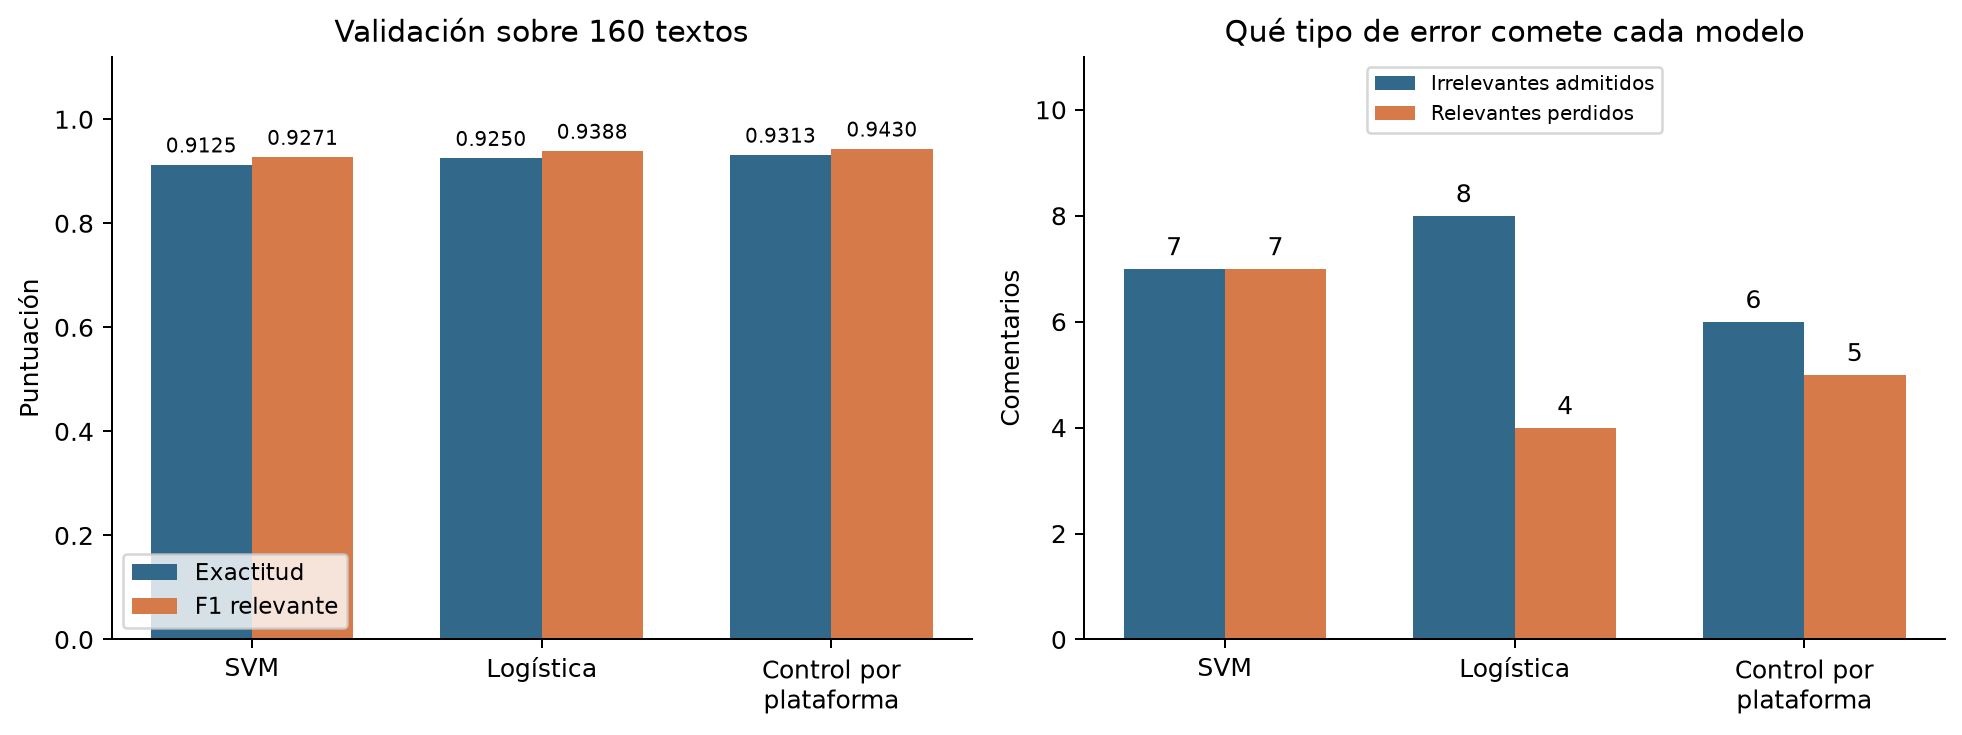

In [5]:
fig,axes=plt.subplots(1,2,figsize=(11,4.2))
x=np.arange(len(relevance));w=.35
for offset,col,label,color in [(-w/2,'accuracy','Exactitud',BLUE),(w/2,'f1_relevant','F1 relevante',ORANGE)]:
 bars=axes[0].bar(x+offset,relevance[col],width=w,label=label,color=color)
 axes[0].bar_label(bars,fmt='%.4f',fontsize=8,padding=3)
axes[0].set(xticks=x,xticklabels=['SVM','Logística','Control por\nplataforma'],ylim=(0,1.12),ylabel='Puntuación',title='Validación sobre 160 textos');axes[0].legend(loc='lower left',fontsize=9)
for offset,col,label,color in [(-w/2,'irrelevant_passed','Irrelevantes admitidos',BLUE),(w/2,'relevant_lost','Relevantes perdidos',ORANGE)]:
 bars=axes[1].bar(x+offset,relevance[col],width=w,label=label,color=color)
 axes[1].bar_label(bars,padding=3)
axes[1].set(xticks=x,xticklabels=['SVM','Logística','Control por\nplataforma'],ylim=(0,11),ylabel='Comentarios',title='Qué tipo de error comete cada modelo');axes[1].legend(loc='upper center',fontsize=8)
axes[0].set_yticks(np.arange(0,1.01,.2))
fig.tight_layout();save_figure(fig,'figura-5-recalculada');show_figure('fig:resultados-relevancia-comparada')

### Los trece comentarios excluidos y la tabla 3

Se conservan los textos completos y la revisión humana registrada: diez exclusiones consideradas irrelevantes y tres consideradas relevantes. Esto describe esos trece casos, no la exactitud global del filtro. Los cinco ejemplos del artículo son los primeros al ordenar por plataforma e identificador. Los recortes editoriales de la tabla no modifican los textos originales de abajo.

In [6]:
removed=read('trece-comentarios-retirados.csv').sort_values(['platform','record_id']).reset_index(drop=True)
check('13 exclusiones únicas',len(removed)==13 and removed.record_id.is_unique)
check('Revisión humana: 10 irrelevantes y 3 relevantes',removed.human_label.value_counts().to_dict()=={'irrelevant':10,'relevant':3})
for row in removed.itertuples():
    display(HTML('<article style="border:1px solid #ccc;padding:10px;margin:8px 0"><b>'+html.escape(row.platform+' · '+row.human_label)+'</b><p style="white-space:pre-wrap">'+html.escape(row.model_text)+'</p></article>'))
show_table('tab:exclusiones')
t=next(t for t in report_tables if t['label']=='tab:exclusiones')
for printed,row in zip(t['rows'],removed.head(5).itertuples()):
    fragments=[x.strip() for x in printed[1].split('[…]') if x.strip()]
    check('Texto de tabla 3 respaldado: '+row.record_id,all(x in row.model_text for x in fragments))


Ejemplos excluidos y revisión humana registrada. […] indica un recorte editorial; se conserva la redacción original.

,Origen,Comentario retirado,Revisión humana
0,X,Si intentaste entrar a tu aplicación de Baname...,Relevante
1,X,Se acuerdan cuando era sencillo comprar un pin...,Irrelevante
2,YouTube,"muchas gracias, muy util la informacion",Irrelevante
3,YouTube,Llamé y fui a sucursal y me confirmaron que es...,Irrelevante
4,YouTube,Sigue sin funcionar,Irrelevante


## 4. Robertuito con transfer learning: evaluación histórica

La fuente es el archivo `evaluation.json` del checkpoint de tiendas v3 indicado en `robertuito-provenance.json`. Se incluye una copia exacta de sus métricas y procedencia. No se requiere acceso a Hugging Face.

Los 14.438 ejemplos de prueba utilizan estrellas como aproximación al sentimiento textual. Recalculamos las métricas del modelo adaptado desde su matriz de confusión y comprobamos la consistencia del informe del modelo original. No disponemos de sus predicciones individuales ni de los IDs del conjunto de entrenamiento para descartar solapamientos con nuestra muestra. **No es una nueva prueba del modelo ni una reproducción de su entrenamiento.**

In [7]:
evaluation=load('robertuito-tiendas-v3-evaluation.json');provenance=load('robertuito-provenance.json')
check('Evaluación histórica: copia exacta del checkpoint',digest(INPUT/'robertuito-tiendas-v3-evaluation.json')==provenance['sha256'])
overall=[];per_class=[]
for name,key in [('Original','baseline_test'),('Tiendas v3','test')]:
    report=evaluation[key]
    overall.append(dict(model=name,accuracy=report['accuracy'],macro_f1=report['macro avg']['f1-score'],test_rows=int(report['macro avg']['support'])))
    for label in LABELS:per_class.append(dict(model=name,label=label,**report[label]))
aggregate=pd.DataFrame(overall);classes=pd.DataFrame(per_class)
check('Evaluación histórica: n=14.438 en ambos modelos',aggregate.test_rows.eq(14438).all())
for model,g in classes.groupby('model'):
    check(model+': soporte y macro-F1 consistentes',g.support.sum()==14438 and np.isclose(g['f1-score'].mean(),aggregate.set_index('model').loc[model,'macro_f1']))
cm=np.asarray(evaluation['confusion_matrix']);check('Matriz histórica: soporte total',cm.sum()==14438)
for i,label in enumerate(evaluation['label_order']):
    precision=cm[i,i]/cm[:,i].sum();recall=cm[i,i]/cm[i].sum();f1=2*precision*recall/(precision+recall)
    for k,v in [('precision',precision),('recall',recall),('f1-score',f1)]:check('Matriz reproduce '+label+' '+k,np.isclose(v,evaluation['test'][label][k]))
check('Exactitud adaptada coincide con matriz',np.isclose(np.trace(cm)/cm.sum(),evaluation['test']['accuracy']))
for model,acc,f1 in [('Original',.7203,.5708),('Tiendas v3',.8910,.6744)]:
    record=aggregate.set_index('model').loc[model]
    check(model+': cifras redondeadas del artículo',abs(record.accuracy-acc)<.00005 and abs(record.macro_f1-f1)<.00005)
check('F1 neutral publicado',round(evaluation['test']['neutral']['f1-score'],4)==.2368)
display(aggregate);display(classes)
aggregate.to_csv(OUT/'sentimiento-historico-recalculado.csv',index=False)
NAMES={'negative':'Negativo','neutral':'Neutral','positive':'Positivo'}


,model,accuracy,macro_f1,test_rows
0,Original,0.720252,0.570764,14438
1,Tiendas v3,0.890982,0.674440,14438


,model,label,precision,recall,f1-score,support
0,Original,negative,0.675155,0.908894,0.774780,3238.0
1,Original,neutral,0.075560,0.223291,0.112912,936.0
2,Original,positive,0.990975,0.706060,0.824600,10264.0
3,Tiendas v3,negative,0.774332,0.894379,0.830037,3238.0
4,Tiendas v3,neutral,0.356223,0.177350,0.236805,936.0
5,Tiendas v3,positive,0.957975,0.954988,0.956479,10264.0


**Figura 6 · calculada** — Prueba histórica con etiquetas derivadas de estrellas. La mejora agregada convive con un F1 neutral bajo; estas métricas no corresponden a la muestra integrada.

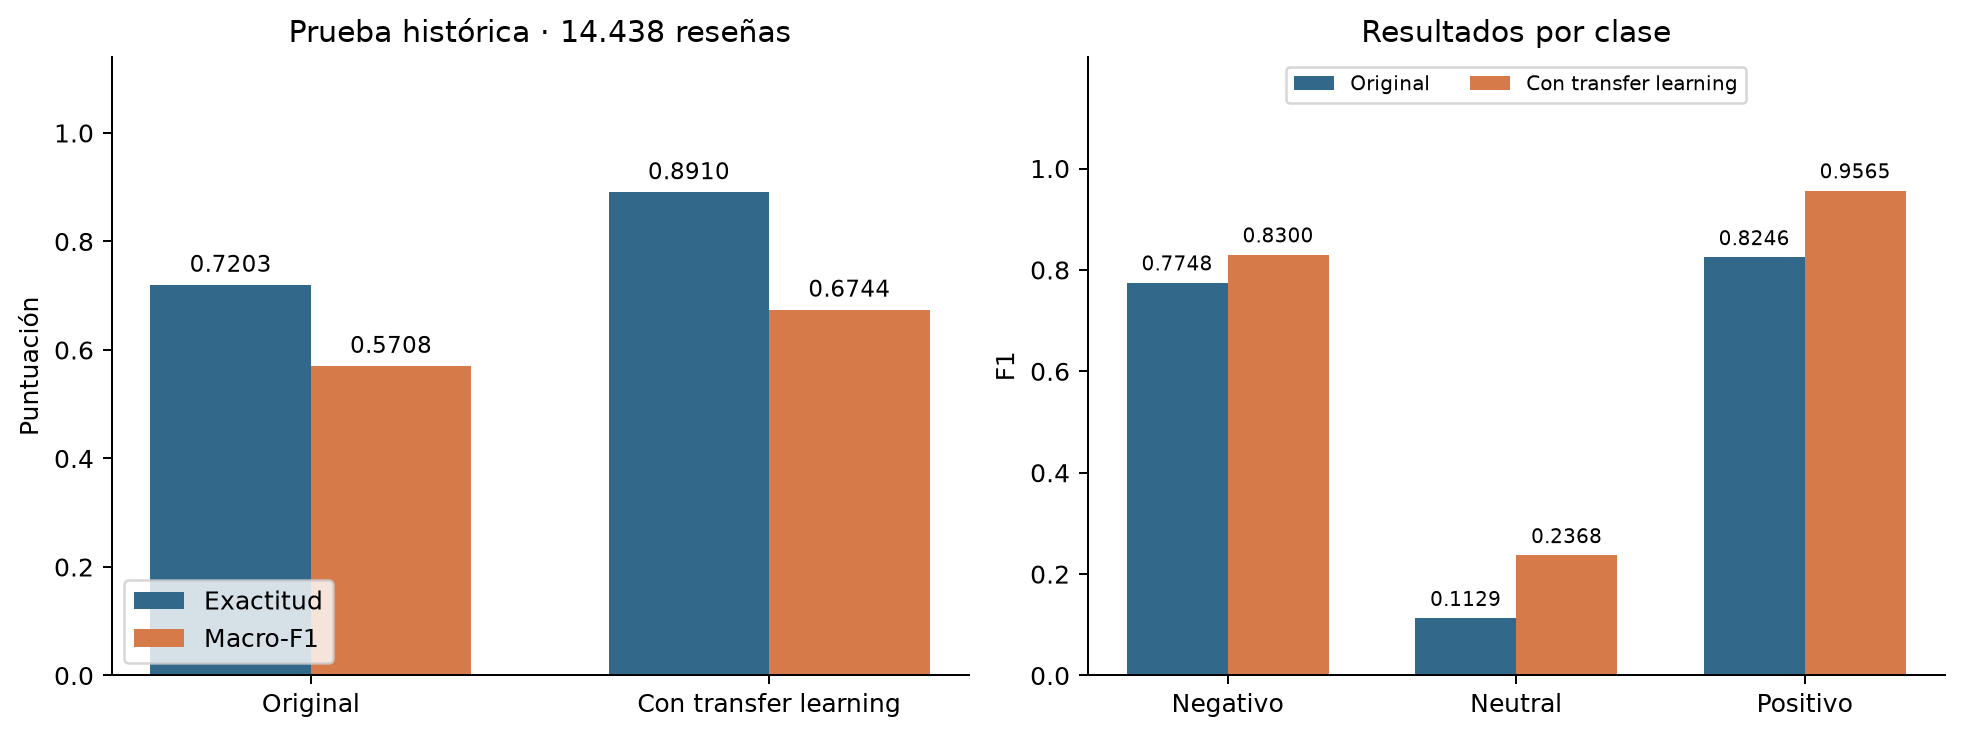

In [8]:
fig,axes=plt.subplots(1,2,figsize=(11,4.2))
x=np.arange(2);w=.35
for offset,col,label,color in [(-w/2,'accuracy','Exactitud',BLUE),(w/2,'macro_f1','Macro-F1',ORANGE)]:
 bars=axes[0].bar(x+offset,aggregate[col],width=w,label=label,color=color);axes[0].bar_label(bars,fmt='%.4f',padding=3,fontsize=9)
axes[0].set(xticks=x,xticklabels=['Original','Con transfer learning'],ylim=(0,1.14),ylabel='Puntuación',title='Prueba histórica · 14.438 reseñas');axes[0].legend(loc='lower left')
x=np.arange(3)
for offset,model,label,color in [(-w/2,'Original','Original',BLUE),(w/2,'Tiendas v3','Con transfer learning',ORANGE)]:
 values=classes.loc[classes.model.eq(model)].set_index('label').loc[LABELS,'f1-score']
 bars=axes[1].bar(x+offset,values,width=w,label=label,color=color);axes[1].bar_label(bars,fmt='%.4f',padding=3,fontsize=8)
axes[1].set(xticks=x,xticklabels=[NAMES[l] for l in LABELS],ylim=(0,1.22),ylabel='F1',title='Resultados por clase');axes[1].legend(loc='upper center',fontsize=8,ncol=2)
axes[0].set_yticks(np.arange(0,1.01,.2))
axes[1].set_yticks(np.arange(0,1.01,.2))
fig.tight_layout();save_figure(fig,'figura-6-recalculada');show_figure('fig:resultados-sentimiento-historico')

In [9]:
training_keys=['training_mode','encoder_blocks_trained','total_parameters','trainable_parameters','trainable_percent','epochs','batch_size','learning_rate','max_length','best_epoch']
display(pd.DataFrame([{k:evaluation[k] for k in training_keys}]))
history=pd.DataFrame(evaluation['history']);display(history)
check('Checkpoint seleccionado por macro-F1 de validación',evaluation['best_epoch']==int(history.loc[history.validation_macro_f1.idxmax(),'epoch']))
thresholds=load('criterios-entrega-anterior.json')
display(Markdown('**Criterio documentado en la entrega anterior, página 50:**\n\n> '+thresholds['text'].split('# Projection')[0].strip()))
neutral=evaluation['test']['neutral']['f1-score']
display(pd.DataFrame([{'comparación':'Macro-F1 adaptado menos original','valor':aggregate.iloc[1].macro_f1-aggregate.iloc[0].macro_f1},{'comparación':'Brecha neutral frente a 0,50','valor':.5-neutral}]))
check('Brecha neutral 0,2632',round(.5-neutral,4)==.2632)
check('Mejora absoluta macro-F1 0,1037',round(aggregate.iloc[1].macro_f1-aggregate.iloc[0].macro_f1,4)==.1037)


,training_mode,encoder_blocks_trained,total_parameters,trainable_parameters,trainable_percent,epochs,batch_size,learning_rate,max_length,best_epoch
0,last_n,1,108791043,7680771,7.060113,3,8,0.00002,128,3


,epoch,loss,validation_macro_f1
0,1,0.335053,0.675600
1,2,0.310442,0.658435
2,3,0.300575,0.681915


**Criterio documentado en la entrega anterior, página 50:**

> Topics should demostrate coherent, relevant groups, based on human-review criteria, a
sentiment target is f1 ≥ 0.65 and per-class F1 ≥ 0.50

,comparación,valor
0,Macro-F1 adaptado menos original,0.103676
1,"Brecha neutral frente a 0,50",0.263195


## 5. Agrupamiento: de las exclusiones a la redistribución

Leemos las asignaciones guardadas de los dos sistemas. Los textos e identificadores permiten seguir el cambio de grupo de cada reseña. La reducción visual común se conserva como resultado guardado: no volvemos a ejecutar UMAP.

Separar **retirar filas de grupos fijos** de **volver a ajustar el agrupamiento** evita atribuir toda diferencia directamente a trece exclusiones. La alternativa también reajustó UMAP/HDBSCAN. Una partición menos concentrada no demuestra mejor calidad temática.

In [10]:
frames={s:read(s+'-asignaciones.csv') for s in ['base','alternative']}
for s,f in frames.items():
    check(s+': una asignación y sentimiento por ID',f.record_id.is_unique and f.model_label.isin(LABELS).all())
base,alt=frames['base'],frames['alternative']
check('La diferencia de entradas son exactamente las 13 exclusiones',set(base.record_id)-set(alt.record_id)==set(removed.record_id) and set(alt.record_id)<=set(base.record_id))
for col in ['model_text','platform']:
    check('Textos y plataformas conservados: '+col,base.set_index('record_id').loc[alt.record_id,col].reset_index(drop=True).equals(alt[col].reset_index(drop=True)))
sample_dates=base[['record_id','platform']].merge(corpus[['record_id','record_date']],on='record_id',validate='one_to_one')
sample_dates['month']=pd.to_datetime(sample_dates.record_date,format='mixed',utc=True).dt.strftime('%Y-%m')
check('Todas las reseñas de la muestra pertenecen a julio–agosto',set(sample_dates.month)=={'2026-07','2026-08'} and len(sample_dates)==1000)
actual_sample=sample_dates.groupby(['month','platform']).size()
for row in sampling.itertuples():check('Estrato de muestra '+row.month+' '+row.platform,actual_sample.loc[(row.month,row.platform)]==row.selected)
printed_sample=next(t for t in report_tables if t['label']=='tab:muestra')
platform_names={'App Store':'app_store','Google Play':'google_play','X':'x','YouTube':'youtube'}
for row in printed_sample['rows'][:-1]:
    plat=platform_names[row[0]]
    observed=[int(actual_sample.loc[(month,plat)]) for month in ['2026-07','2026-08']]+[int(base.platform.eq(plat).sum()),int(alt.platform.eq(plat).sum())]
    check('Tabla 1 coincide: '+plat,observed==[int(x) for x in row[1:]])
structure=[]
for s,f in frames.items():
    sizes=f.loc[f.topic_id.ge(0)].groupby('topic_id').size()
    structure.append(dict(system=s,rows=len(f),topics=len(sizes),unassigned=int(f.topic_id.eq(-1).sum()),unassigned_pct=100*f.topic_id.eq(-1).mean(),largest=int(sizes.max())))
structure=pd.DataFrame(structure).set_index('system')
check('Base: 1000 / 18 / 47 / 529',structure.loc['base',['rows','topics','unassigned','largest']].tolist()==[1000,18,47,529])
check('Alternativa: 987 / 28 / 141 / 105',structure.loc['alternative',['rows','topics','unassigned','largest']].tolist()==[987,28,141,105])
check('Porcentajes sin tópico del reporte',round(structure.loc['base','unassigned_pct'],2)==4.70 and round(structure.loc['alternative','unassigned_pct'],2)==14.29)
display(structure);structure.to_csv(OUT/'agrupamiento-recalculado.csv')
common=base.merge(alt,on='record_id',suffixes=('_base','_alt'),validate='one_to_one')
check('314 cambios de sentimiento sobre 987 textos comunes',len(common)==987 and common.model_label_base.ne(common.model_label_alt).sum()==314)
removed_only=base[base.record_id.isin(alt.record_id)]
display(Markdown('**Control descriptivo: retirar filas sin reajustar**'))
display(removed_only.groupby('topic_id').size().rename('reseñas'))
check('Sin reajustar, el mayor grupo conservaría 518 reseñas',removed_only[removed_only.topic_id.ge(0)].groupby('topic_id').size().max()==518)
biggest=base[base.topic_id.ge(0)].groupby('topic_id').size().idxmax()
flow=common[common.topic_id_base.eq(biggest)].groupby('topic_id_alt').size().rename('reseñas').reset_index()
check('El grupo mayor conservado se reparte y tiene casos sin tópico',len(flow)>2 and -1 in flow.topic_id_alt.values and flow.reseñas.sum()==518)
display(Markdown('**Destino de las reseñas conservadas del mayor tópico base**'));display(flow)
flow.to_csv(OUT/'redistribucion-grupo-mayor.csv',index=False)


,rows,topics,unassigned,unassigned_pct,largest
system,,,,,
base,1000,18,47,4.700000,529
alternative,987,28,141,14.285714,105


**Control descriptivo: retirar filas sin reajustar**

topic_id
-1      47
 0     518
 1      56
 2      38
 3      34
 4      30
 5      30
 6      30
 7      28
 8      25
 9      23
 10     20
 11     22
 12     17
 13     17
 14     15
 15     13
 16     13
 17     11
Name: reseñas, dtype: int64

**Destino de las reseñas conservadas del mayor tópico base**

,topic_id_alt,reseñas
0,-1,96
1,0,105
2,1,73
3,2,66
4,3,60
5,6,1
6,11,25
7,13,24
8,14,22
9,18,17


**Figura 4 · calculada** — Proyección común de los embeddings. Se distinguen los seis tópicos mayores de cada sistema; gris: otros tópicos; cruces: sin asignación. Los colores no emparejan temas. Los ejes UMAP no tienen unidades físicas y no son el espacio de agrupamiento.

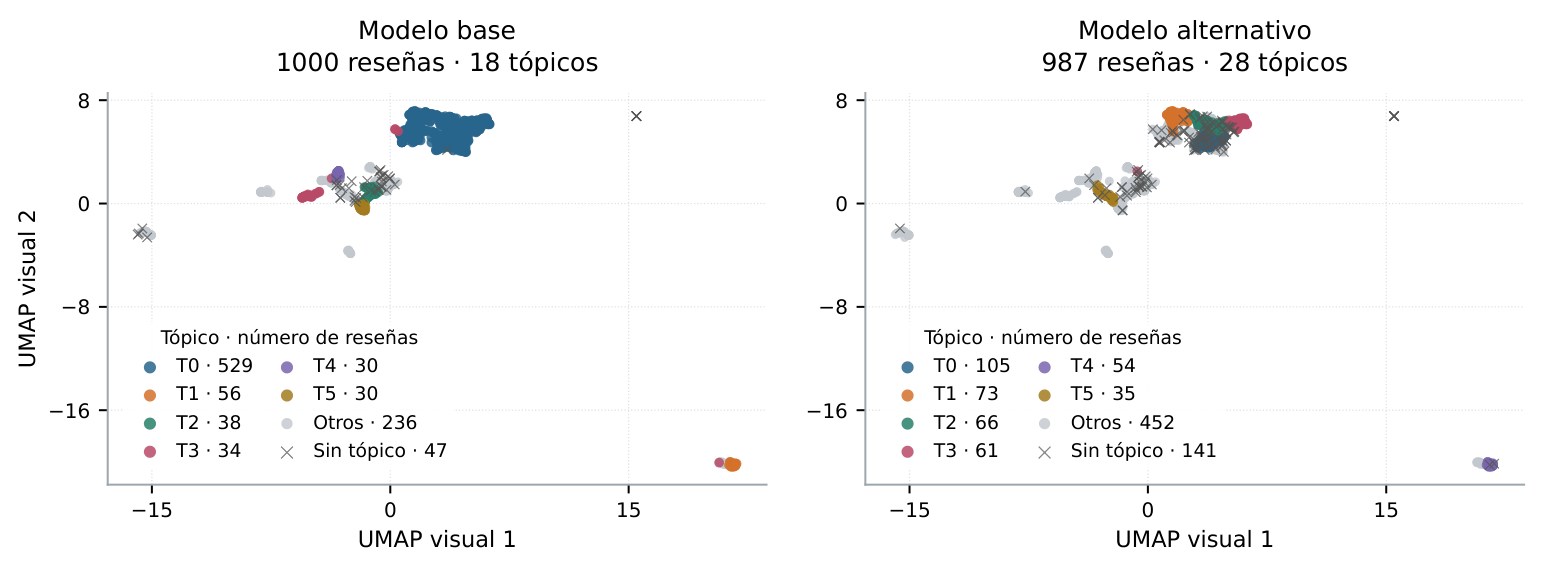

**Figura 7 · calculada** — Distribución por tamaño con la misma escala vertical. Izquierda: modelo base (azul). Derecha: alternativa (naranja). Las posiciones no emparejan temas. Se excluyen las reseñas sin tópico.

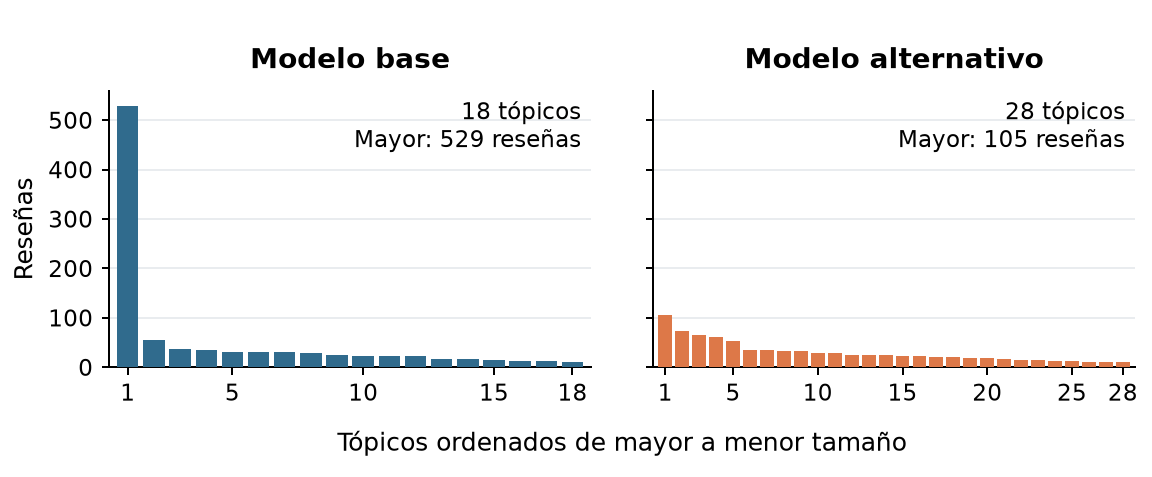

In [11]:
coords=read('proyeccion-comun.csv');visual_receipt=load('proyeccion-recibo.json')
check('Coordenadas guardadas íntegras',digest(INPUT/'proyeccion-comun.csv')==visual_receipt['coordinates_sha256'])
check('Proyección común cubre la muestra',coords.record_id.is_unique and set(coords.record_id)==set(base.record_id))
fig,axes=plt.subplots(1,2,figsize=(10,4),sharex=True,sharey=True)
for ax,s in zip(axes,frames):
    f=frames[s].merge(coords,on='record_id',validate='one_to_one')
    top=f.loc[f.topic_id.ge(0)].topic_id.value_counts().head(6).index
    ax.scatter(f.visual_x,f.visual_y,c='#d2d5d8',s=9,alpha=.6,label='Otros tópicos')
    for i,t in enumerate(top):
        g=f[f.topic_id.eq(t)];ax.scatter(g.visual_x,g.visual_y,s=10,color=plt.cm.tab10(i),label=f'T{t} (n={len(g)})',alpha=.75)
    g=f[f.topic_id.eq(-1)];ax.scatter(g.visual_x,g.visual_y,marker='x',color='#555',s=12,label='Sin tópico')
    ax.set(title='Base' if s=='base' else 'Alternativa',xlabel='UMAP visual 1');ax.legend(fontsize=6,loc='best')
axes[0].set_ylabel('UMAP visual 2');fig.tight_layout();save_figure(fig,'figura-4-recalculada')
show_figure('fig:hdbscan-base-alternativa')

fig,axes=plt.subplots(1,2,figsize=(8,3),sharey=True,layout='constrained')
for ax,s,col in zip(axes,frames,[BLUE,ORANGE]):
    sizes=frames[s].loc[frames[s].topic_id.ge(0)].groupby('topic_id').size().sort_values(ascending=False)
    ax.bar(range(1,len(sizes)+1),sizes,color=col)
    ax.set(title=('Modelo base' if s=='base' else 'Modelo alternativo'),xlabel='Tópicos ordenados por tamaño',ylim=(0,560))
axes[0].set_ylabel('Reseñas');save_figure(fig,'figura-7-recalculada')
show_figure('fig:resultados-distribucion-combinada')


## 6. Nombres del LLM y sentimiento por tópico — anexo A

El catálogo del artículo corresponde a las salidas guardadas del recorrido paso a paso, no a una mezcla de ejecuciones. Los nombres se cotejan con su tabla de interpretaciones y los tamaños y colores se reconstruyen desde las asignaciones por reseña.

**La especificidad es una percepción subjetiva del equipo.** No inferimos calidad por contar más tópicos. El sentimiento corresponde a la reseña completa y no permite atribuir polaridades diferentes a varios aspectos del mismo comentario.

,system,topic_id,name,size,negative,neutral,positive
0,alternative,0,Problemas de acceso y navegación en la aplicación,105,81,14,10
1,alternative,1,Problemas de acceso y visualización de movimie...,73,55,9,9
2,alternative,2,Problemas de rendimiento y acceso a la aplicación,66,55,4,7
3,alternative,3,Problemas de acceso y registro en la aplicació...,61,49,1,11
4,alternative,4,Reseñas de satisfacción general,54,0,0,54
5,alternative,5,Mejora en la rapidez y eficiencia de la aplica...,35,1,0,34
6,alternative,6,Servicio y atención al cliente,34,0,0,34
7,alternative,7,Funcionamiento general de la aplicación,32,1,0,31
8,alternative,8,Mejoras en la velocidad y funcionalidad de la ...,32,3,0,29
9,alternative,9,Calidad general de la aplicación,29,0,0,29


system,topic_id,name,size,negative,neutral,positive
alternative,0,Problemas de acceso y navegación en la aplicación,105,81,14,10
alternative,1,Problemas de acceso y visualización de movimientos,73,55,9,9
alternative,2,Problemas de rendimiento y acceso a la aplicación,66,55,4,7
alternative,3,Problemas de acceso y registro en la aplicación móvil de Banamex,61,49,1,11
alternative,4,Reseñas de satisfacción general,54,0,0,54
alternative,5,Mejora en la rapidez y eficiencia de la aplicación,35,1,0,34
alternative,6,Servicio y atención al cliente,34,0,0,34
alternative,7,Funcionamiento general de la aplicación,32,1,0,31
alternative,8,Mejoras en la velocidad y funcionalidad de la aplicación,32,3,0,29
alternative,9,Calidad general de la aplicación,29,0,0,29


**Figura A.1 · calculada** — Catálogo completo de tópicos. Izquierda: modelo base. Derecha: modelo alternativo. Longitud de las barras: número de reseñas. Colores: sentimiento por reseña. Las filas no emparejan temas y los nombres del LLM no son etiquetas humanas validadas.

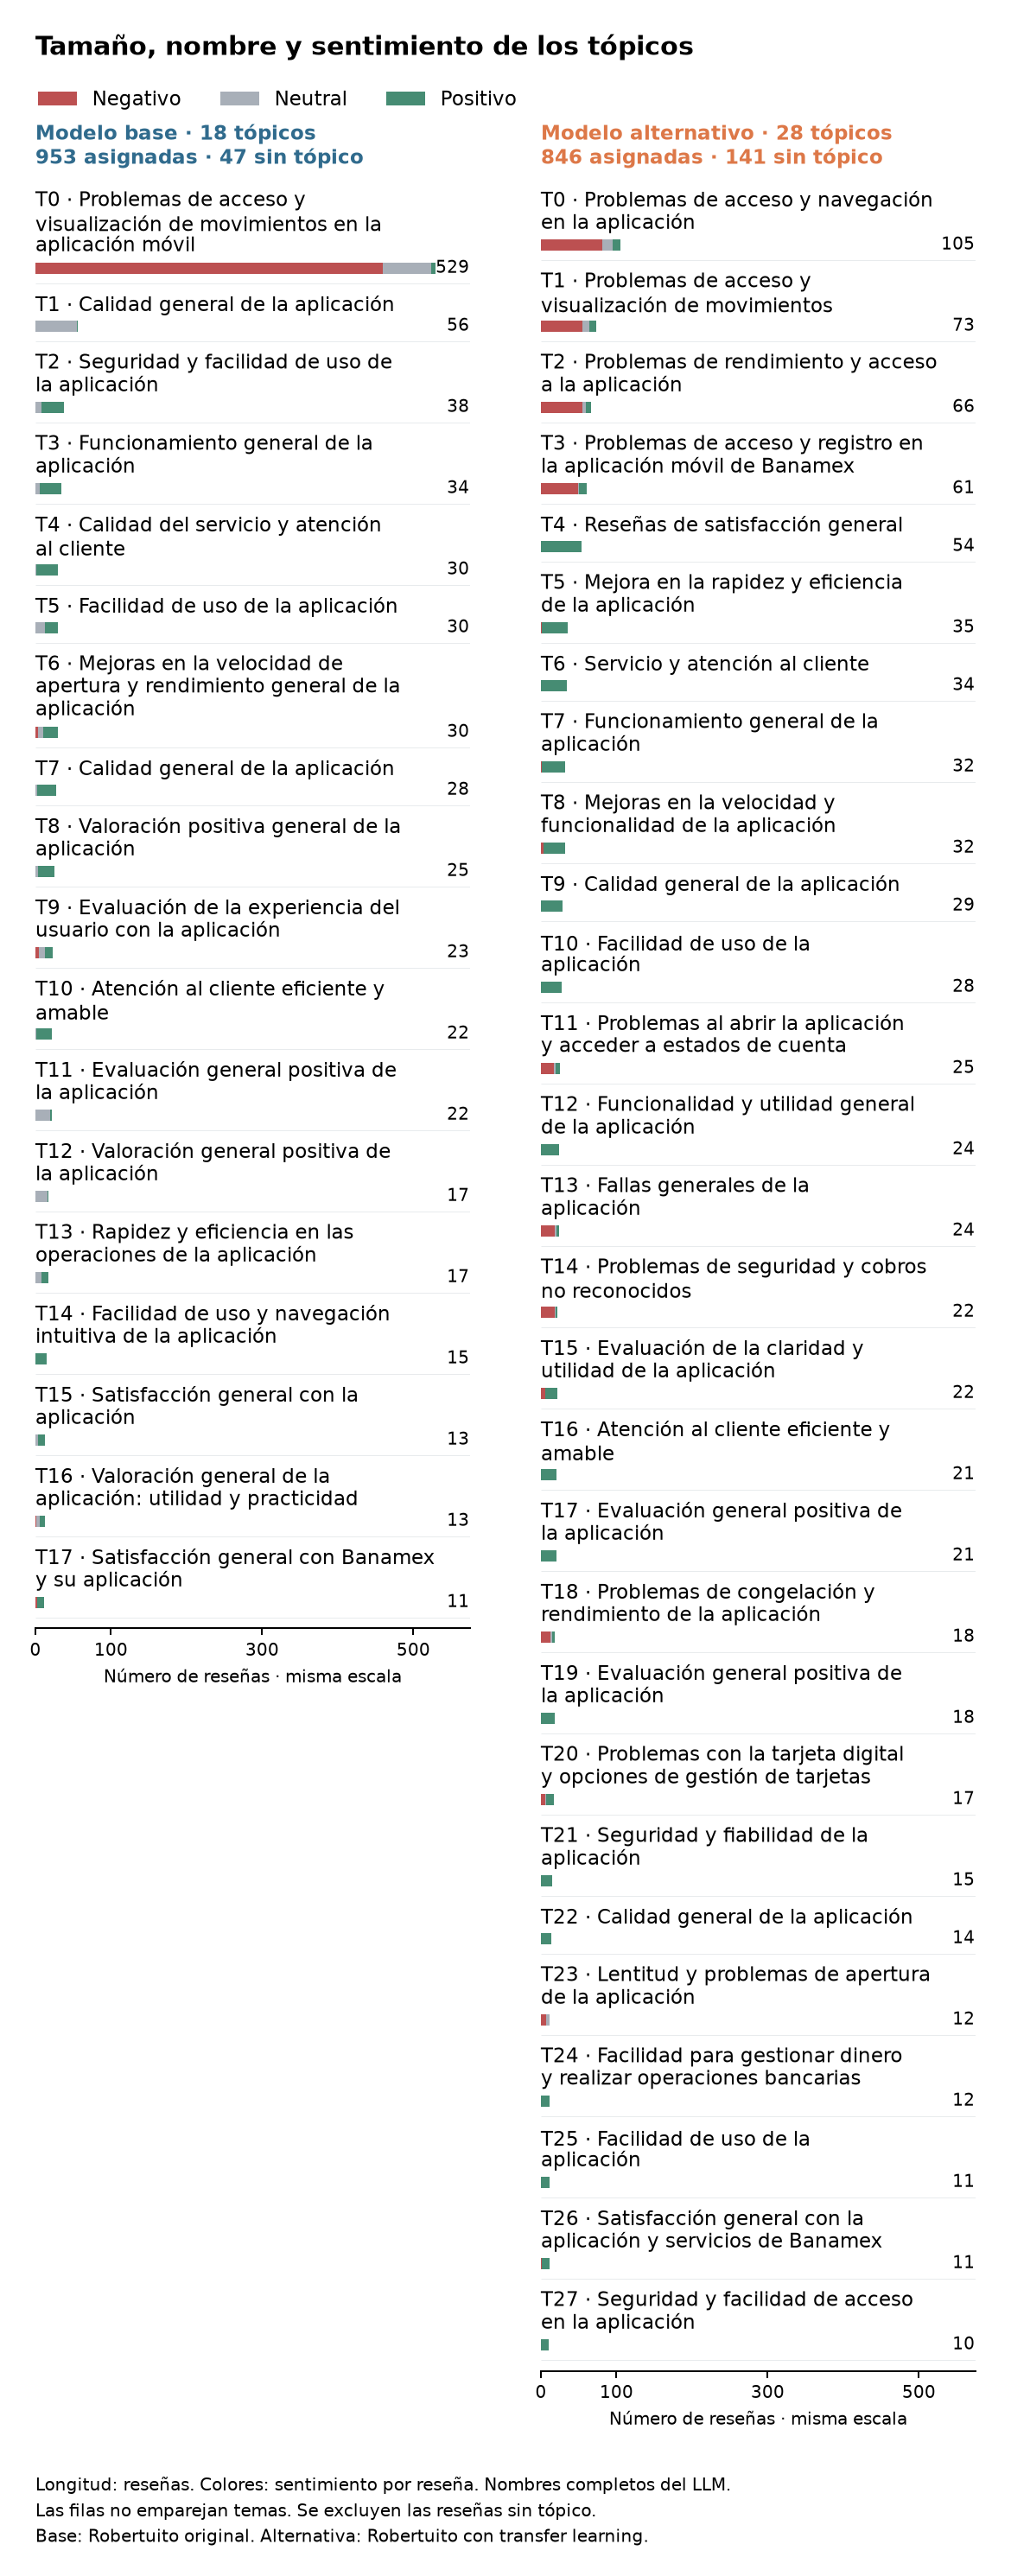

In [12]:
published=read('catalogo-publicado.csv').sort_values(['system','topic_id']).reset_index(drop=True)
interpretations=read('interpretaciones.csv')
rebuilt=[]
for s,f in frames.items():
    topics=read(s+'-topicos-palabras-llm.csv');topics=topics[topics.topic_id.ge(0)]
    for row in topics.itertuples():
        members=f[f.topic_id.eq(row.topic_id)];sent=members.model_label.value_counts().reindex(LABELS,fill_value=0)
        stored=interpretations[(interpretations.system==s)&(interpretations.topic_id==row.topic_id)].iloc[0]
        check(f'{s} T{row.topic_id}: nombre coincide con la interpretación guardada',row.name==stored['name'])
        check(f'{s} T{row.topic_id}: tamaño coincide',row.size==len(members))
        rebuilt.append(dict(system=s,topic_id=row.topic_id,name=row.name,size=len(members),**sent.to_dict()))
catalog=pd.DataFrame(rebuilt).sort_values(['system','topic_id']).reset_index(drop=True)
cols=['system','topic_id','name','size',*LABELS]
check('Los 46 nombres, tamaños y tres sentimientos del anexo coinciden',catalog[cols].equals(published[cols]))
check('953 y 846 asignaciones conservadas',catalog.groupby('system')['size'].sum().to_dict()=={'alternative':846,'base':953})
display(catalog);catalog.to_csv(OUT/'catalogo-recalculado.csv',index=False)
# Una tabla legible también permite buscar los nombres completos sin ampliar la imagen.
display(HTML(catalog.to_html(index=False,escape=True)))
show_figure('fig:anexo-topicos-sentimiento')


In [13]:
rows=read('catalogo-publicado.csv').to_dict('records')
from matplotlib.patches import Patch
plt.rcParams.update({'font.family':'DejaVu Sans','svg.fonttype':'none','pdf.fonttype':42})
groups={s:sorted([r for r in rows if r['system']==s],key=lambda r:(-int(r['size']),int(r['topic_id']))) for s in ['base','alternative']}
def render(groups,suffix='',part=0):
 layouts={}
 for system,group in groups.items():
  cursor=0;items=[]
  for r in group:
   lines=textwrap.wrap(f"T{r['topic_id']} · {r['name']}",width=38,break_long_words=False,break_on_hyphens=False)
   bar_y=cursor+len(lines)*10.8+4
   items.append((r,'\n'.join(lines),cursor,bar_y))
   cursor=bar_y+12
  layouts[system]=(items,cursor)
 header=88;footer=28 if part else 95;body=max(v[1] for v in layouts.values());height=(header+body+footer)/72
 fig=plt.figure(figsize=(6.5,height))
 colors=['#BC5051','#A8AFB8','#468C73'];fields=['negative','neutral','positive']
 fig.text(.035,1-16/(height*72),'Tamaño, nombre y sentimiento de los tópicos'+(' (continuación)' if part==2 else ''),fontsize=11 if part==2 else 12,fontweight='bold',va='top')
 fig.legend([Patch(facecolor=c) for c in colors],['Negativo','Neutral','Positivo'],loc='upper left',bbox_to_anchor=(.02,1-34/(height*72)),ncol=3,frameon=False,fontsize=9)
 labels=[]
 for left,system,title,color in zip([.035,.535],groups,['Modelo base','Modelo alternativo'],['#306B8D','#DD7848']):
  items,total=layouts[system]
  ax=fig.add_axes([left,1-(header+total)/(height*72),.43,total/(height*72)])
  ax.set_xlim(0,575);ax.set_ylim(total,0)
  count=953 if system=='base' else 846;noise=47 if system=='base' else 141
  full_count=18 if system=='base' else 28
  ax.set_title(f'{title} · {full_count} tópicos'+f'\n{count} asignadas · {noise} sin tópico',fontsize=9,color=color,pad=12,loc='left',fontweight='bold')
  for r,name,y,bar_y in items:
   labels.append(ax.text(0,y,name,fontsize=9,va='top',ha='left',linespacing=1.15))
   start=0
   for field,c in zip(fields,colors):
    v=int(r[field]);ax.barh(bar_y,v,left=start,height=5.5,color=c,zorder=3);start+=v
   assert start==int(r['size'])
   ax.text(574,bar_y,r['size'],ha='right',va='center',fontsize=8)
   ax.hlines(bar_y+7,0,575,color='#e5e9eb',linewidth=.35)
  ax.set_yticks([]);ax.set_xticks([0,100,300,500]);ax.tick_params(axis='x',labelsize=8,length=3)
  ax.set_xlabel('Número de reseñas · misma escala',fontsize=8)
  ax.spines[['top','right','left']].set_visible(False)
 if not part:
  fig.text(.035,12/(height*72),'Longitud: reseñas. Colores: sentimiento por reseña. Nombres completos del LLM.\nLas filas no emparejan temas. Se excluyen las reseñas sin tópico.\nBase: Robertuito original. Alternativa: Robertuito con transfer learning.',fontsize=8,va='bottom',linespacing=1.5)
 fig.canvas.draw();renderer=fig.canvas.get_renderer()
 for t in labels:
  box=t.get_window_extent(renderer)
  assert box.x1<=t.axes.bbox.x1+1, f'Nombre excede panel: {t.get_text()}'
 for ext in (['pdf'] if part else ['svg','png','pdf']):
  fig.savefig(OUT/f'figura8-combinada-horizontal{suffix}.{ext}',dpi=180,facecolor='white')
 
 plt.close(fig)

render(groups)
for part in [1,2]:
 render({k:v[(part-1)*14:part*14] for k,v in groups.items()},f'-parte-{part}',part)
print('Catálogo completo y dos partes para impresión generados sin nueva inferencia.')


Catálogo completo y dos partes para impresión generados sin nueva inferencia.


## 7. Implementación, operación y costos

Los diagramas de arquitectura y ReAct son recursos documentales. La captura del dashboard muestra una publicación de **80.079 reseñas y 110 temas**, distinta de la comparación de 1.000 reseñas. La utilidad comunicada por el patrocinador es feedback cualitativo del equipo, no una evaluación controlada de usabilidad.

Recalculamos los costos desde un extracto de los registros de OpenRouter que conserva únicamente el modelo y el costo por llamada. No contiene nombres de claves, usuarios ni credenciales. Los escenarios de 1.000 preguntas suponen 2, 4 o 6 llamadas por pregunta: **no son costos observados por pregunta ni límites de gasto**. No incluyen AWS ni el costo del equipo local.

,calls,total_usd,mean_usd
model,,,
Claude,184,1.172682,0.006373271739130434782608695652
Gemini,210,0.147749,0.0007035666666666666666666666667


,calls_per_question,questions,calls,estimated_usd
0,2,1000,2000,12.75
1,4,1000,4000,25.49
2,6,1000,6000,38.24


Requisitos y roles propuestos. Antes de ampliar acceso deben validarse concurrencia, respaldo y restauración.

,Requisito,Responsable propuesto,Qué supervisar o comprobar
0,Actualizar y publicar,Operador de datos,"Antigüedad por fuente, fallos de pipeline e in..."
1,Revisar resultados,Analista y responsable de modelos,"Exclusiones relevantes, errores de sentimiento..."
2,Mantener el servicio,Responsable de plataforma,"Disponibilidad, permisos, concurrencia y resta..."
3,Controlar uso externo,Responsable de operación,"Consumo, fallos y límites de llamadas; autoriz..."


Consumo observado durante el desarrollo. No incluye AWS ni recursos locales; sin cargo por API no significa costo total nulo.

,Componente,Ejecución,Cargo por API del modelo
0,"MiniLM, filtro y agrupamiento BERTopic",Local,Sin cargo por API.
1,Robertuito,Local,Sin cargo por API.
2,Interpretación BERTopic · Gemini 2.5 Flash,"Externa, durante el análisis","USD 0,000704 por llamada, en promedio."
3,Dashboard,Consulta datos calculados,Sin invocar un LLM.
4,Agentes · Claude Sonnet 5.5,"Externa, durante el chat","USD 0,006373 por llamada, en promedio."


Escenarios con consumo medio constante. No son costos medidos por pregunta ni límites máximos.

,Llamadas por pregunta,Llamadas para 1.000 preguntas,Costo estimado (USD)
0,2,2.000,"12,75"
1,4,4.000,"25,49"
2,6,6.000,"38,24"


**Figura 8 · documental** — Arquitectura del prototipo. El operador publica resultados; voc CLI y la aplicación reutilizan la biblioteca de consulta en entornos distintos. Los clientes acceden a los servicios de la aplicación.

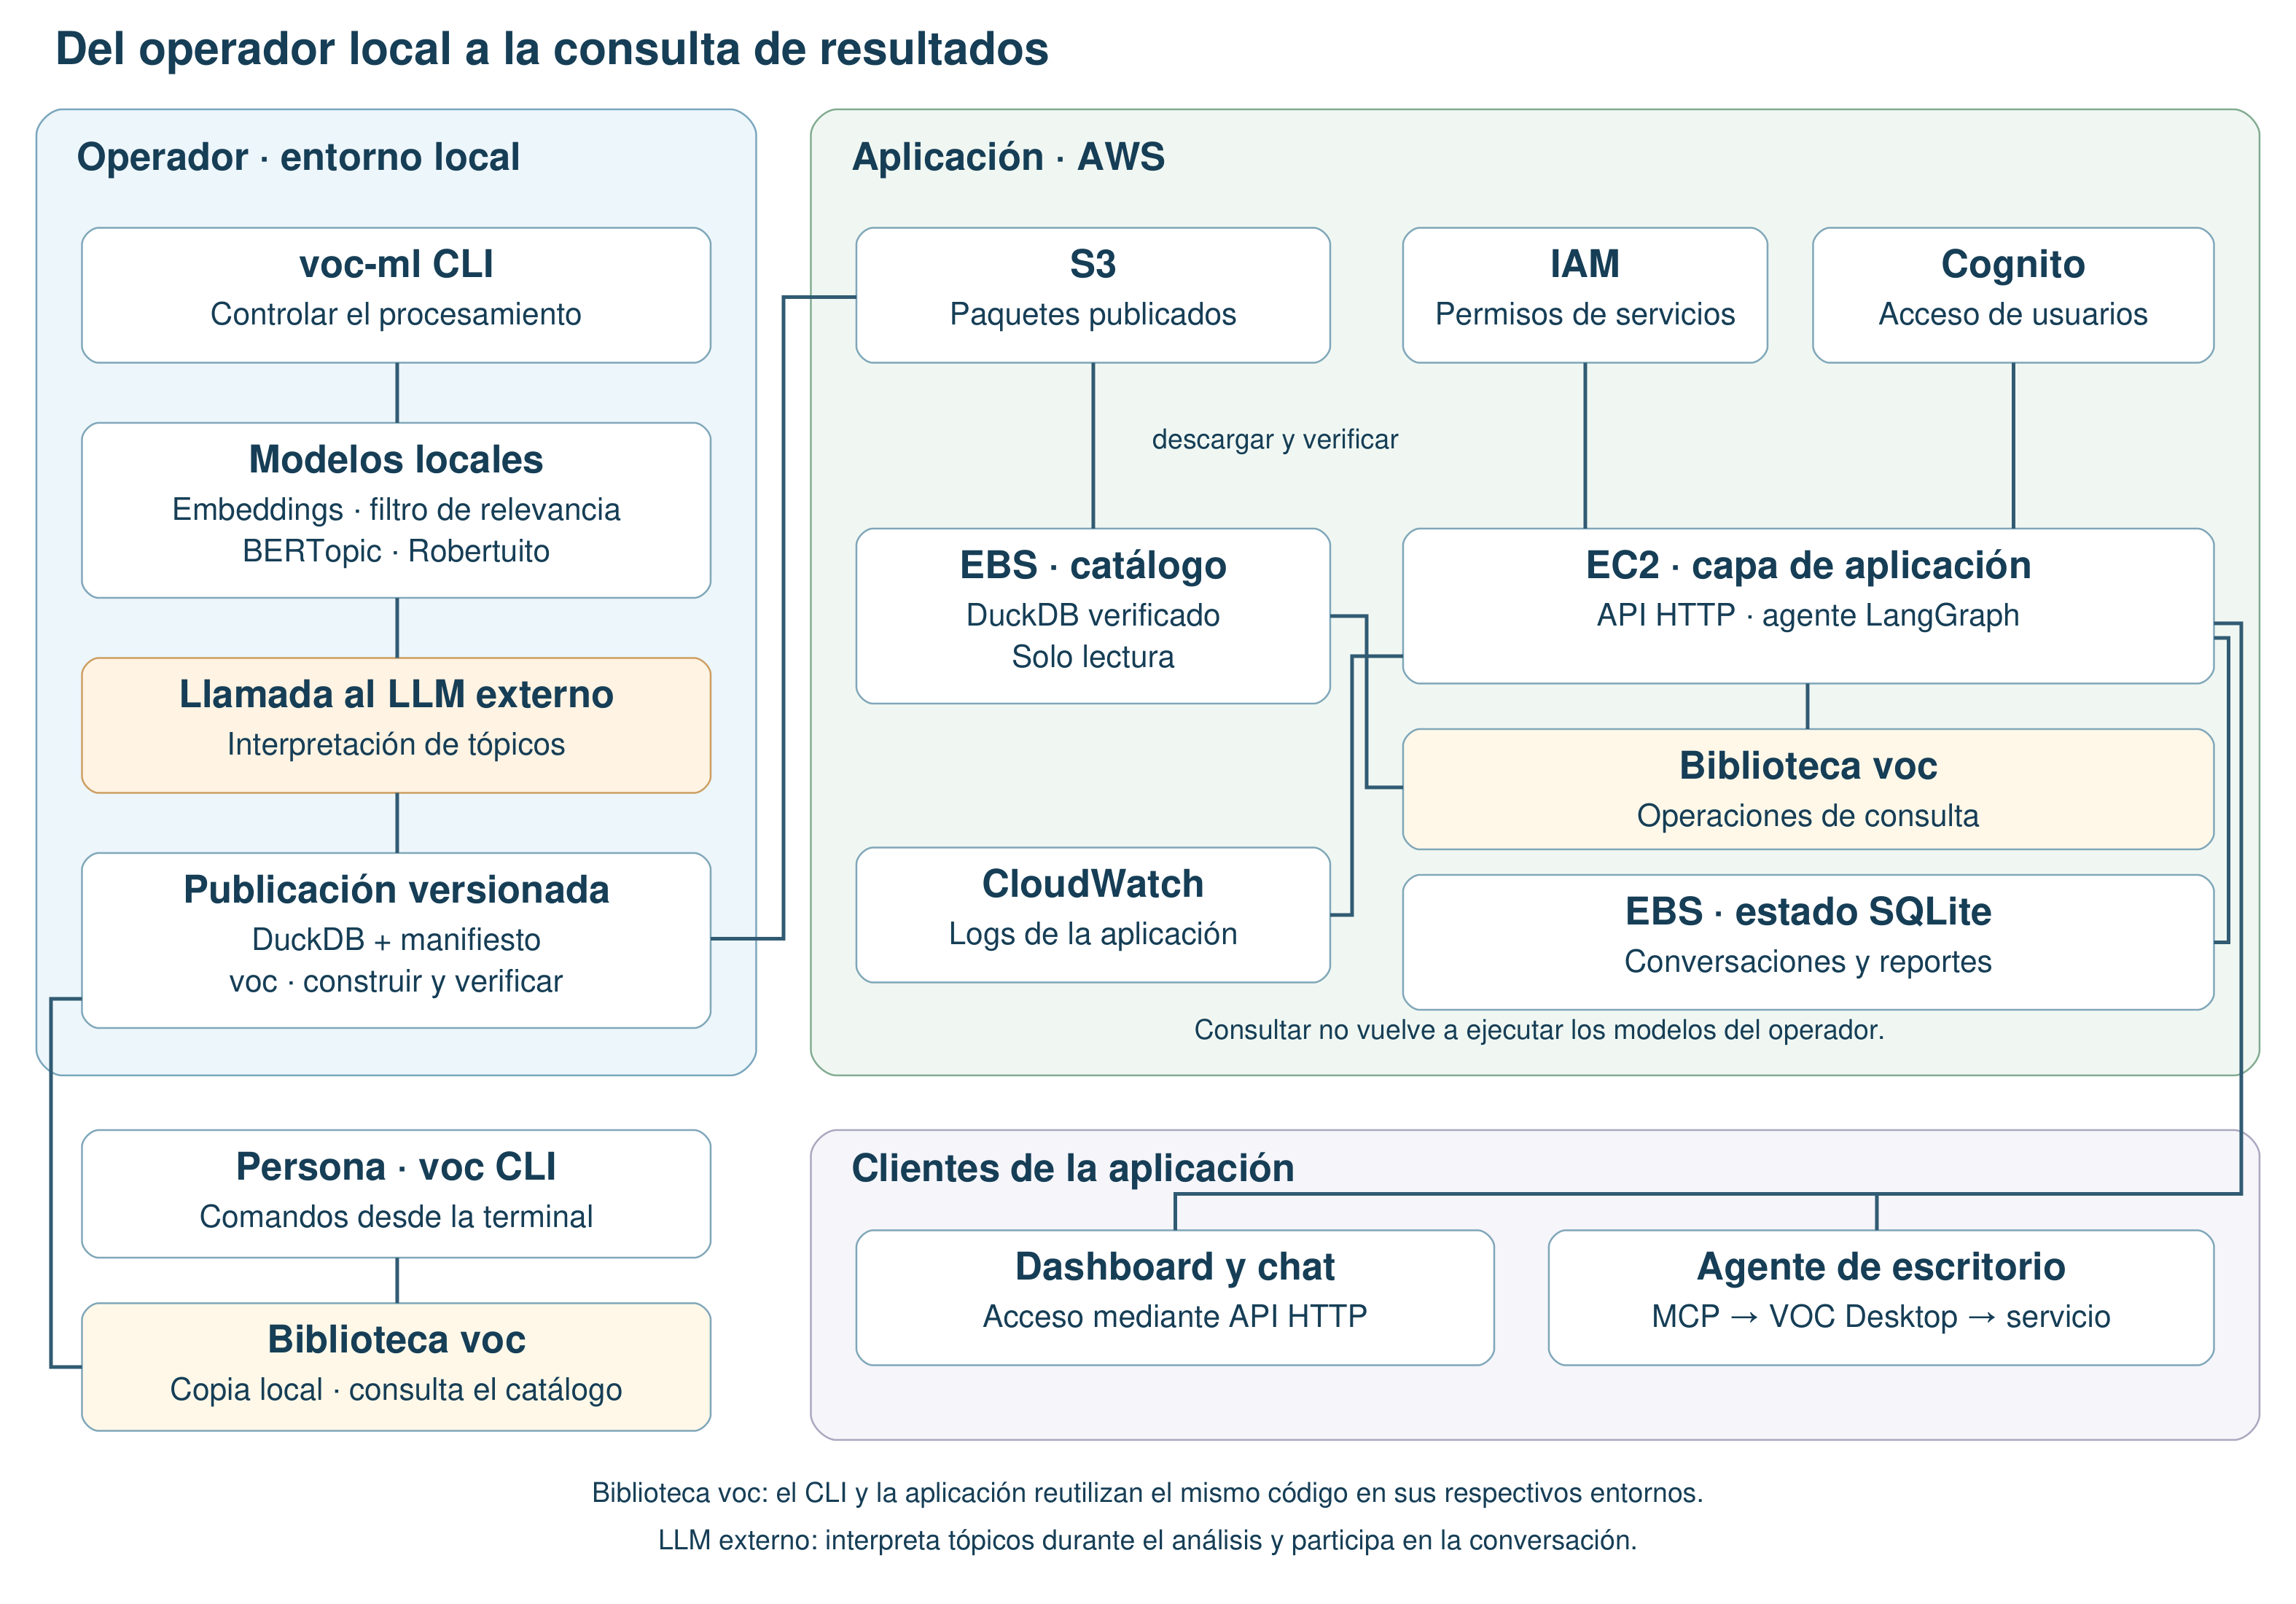

**Figura 9 · documental** — Ciclo conceptual de consulta basado en ReAct. El agente evalúa la evidencia y continúa dentro de límites o responde con referencias; no sustituye la interpretación del analista.

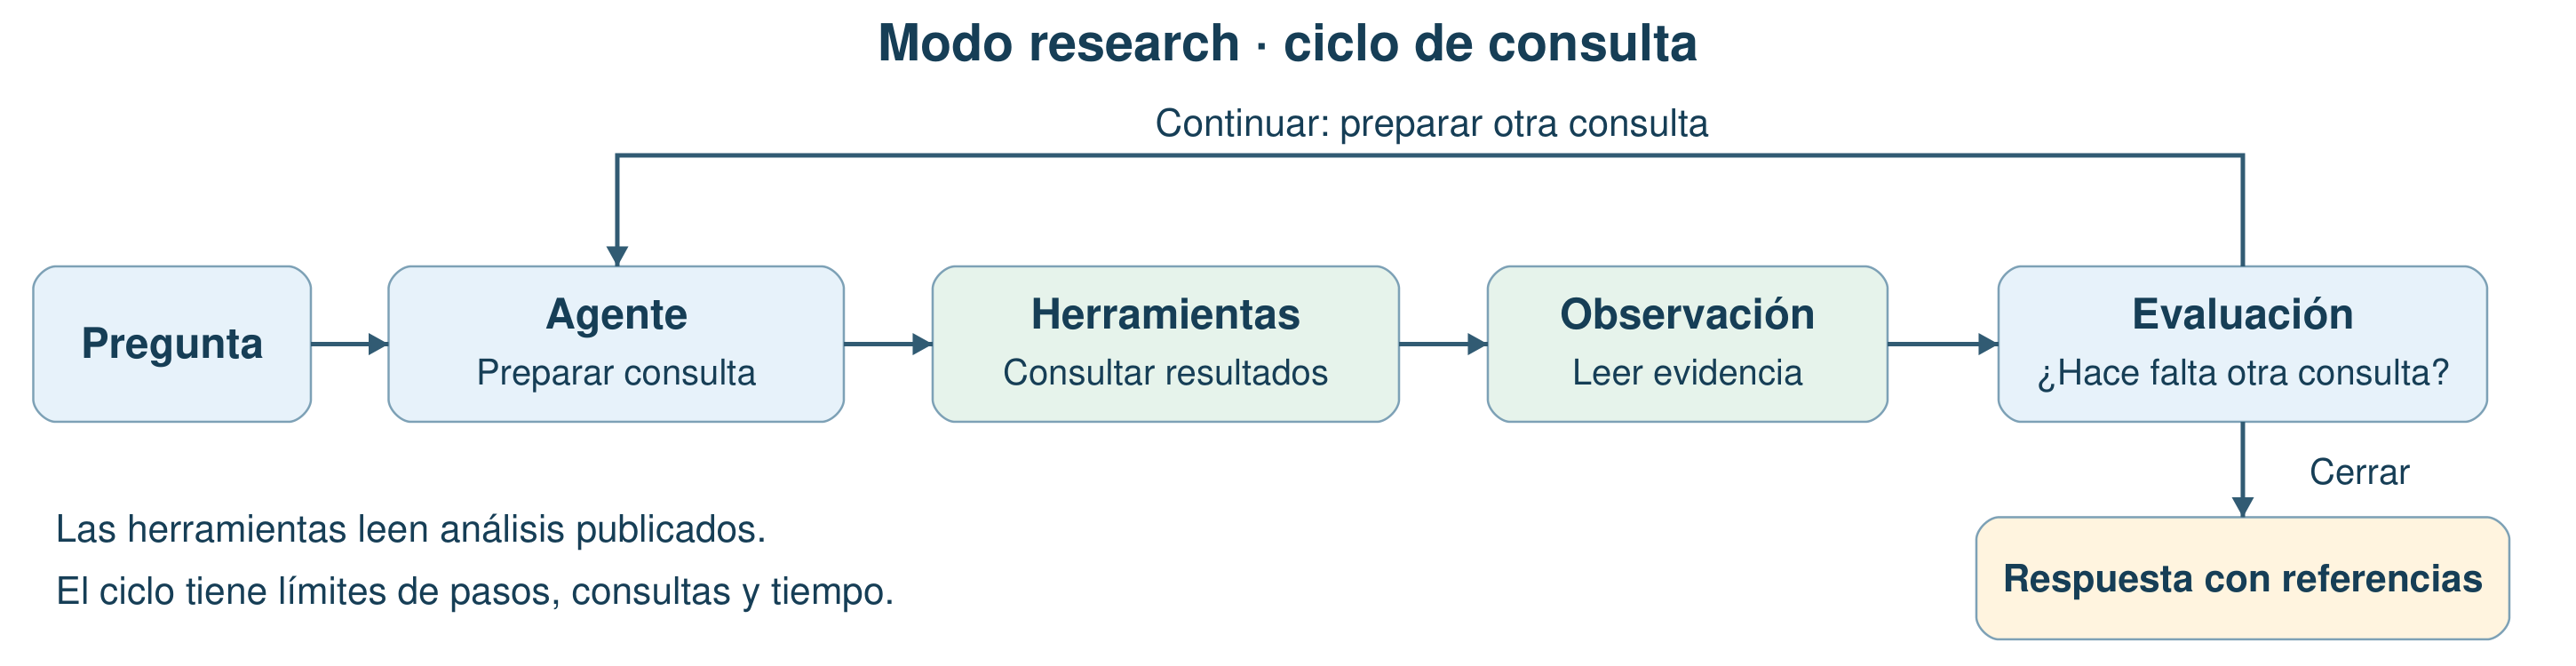

**Figura B.1 · documental** — Dashboard del prototipo para explorar temas, sentimiento y reseñas mediante filtros. La captura ilustra la interfaz con una publicación de 80.079 reseñas y 110 temas, distinta de la muestra de 1.000 reseñas utilizada en la comparación de este artículo.

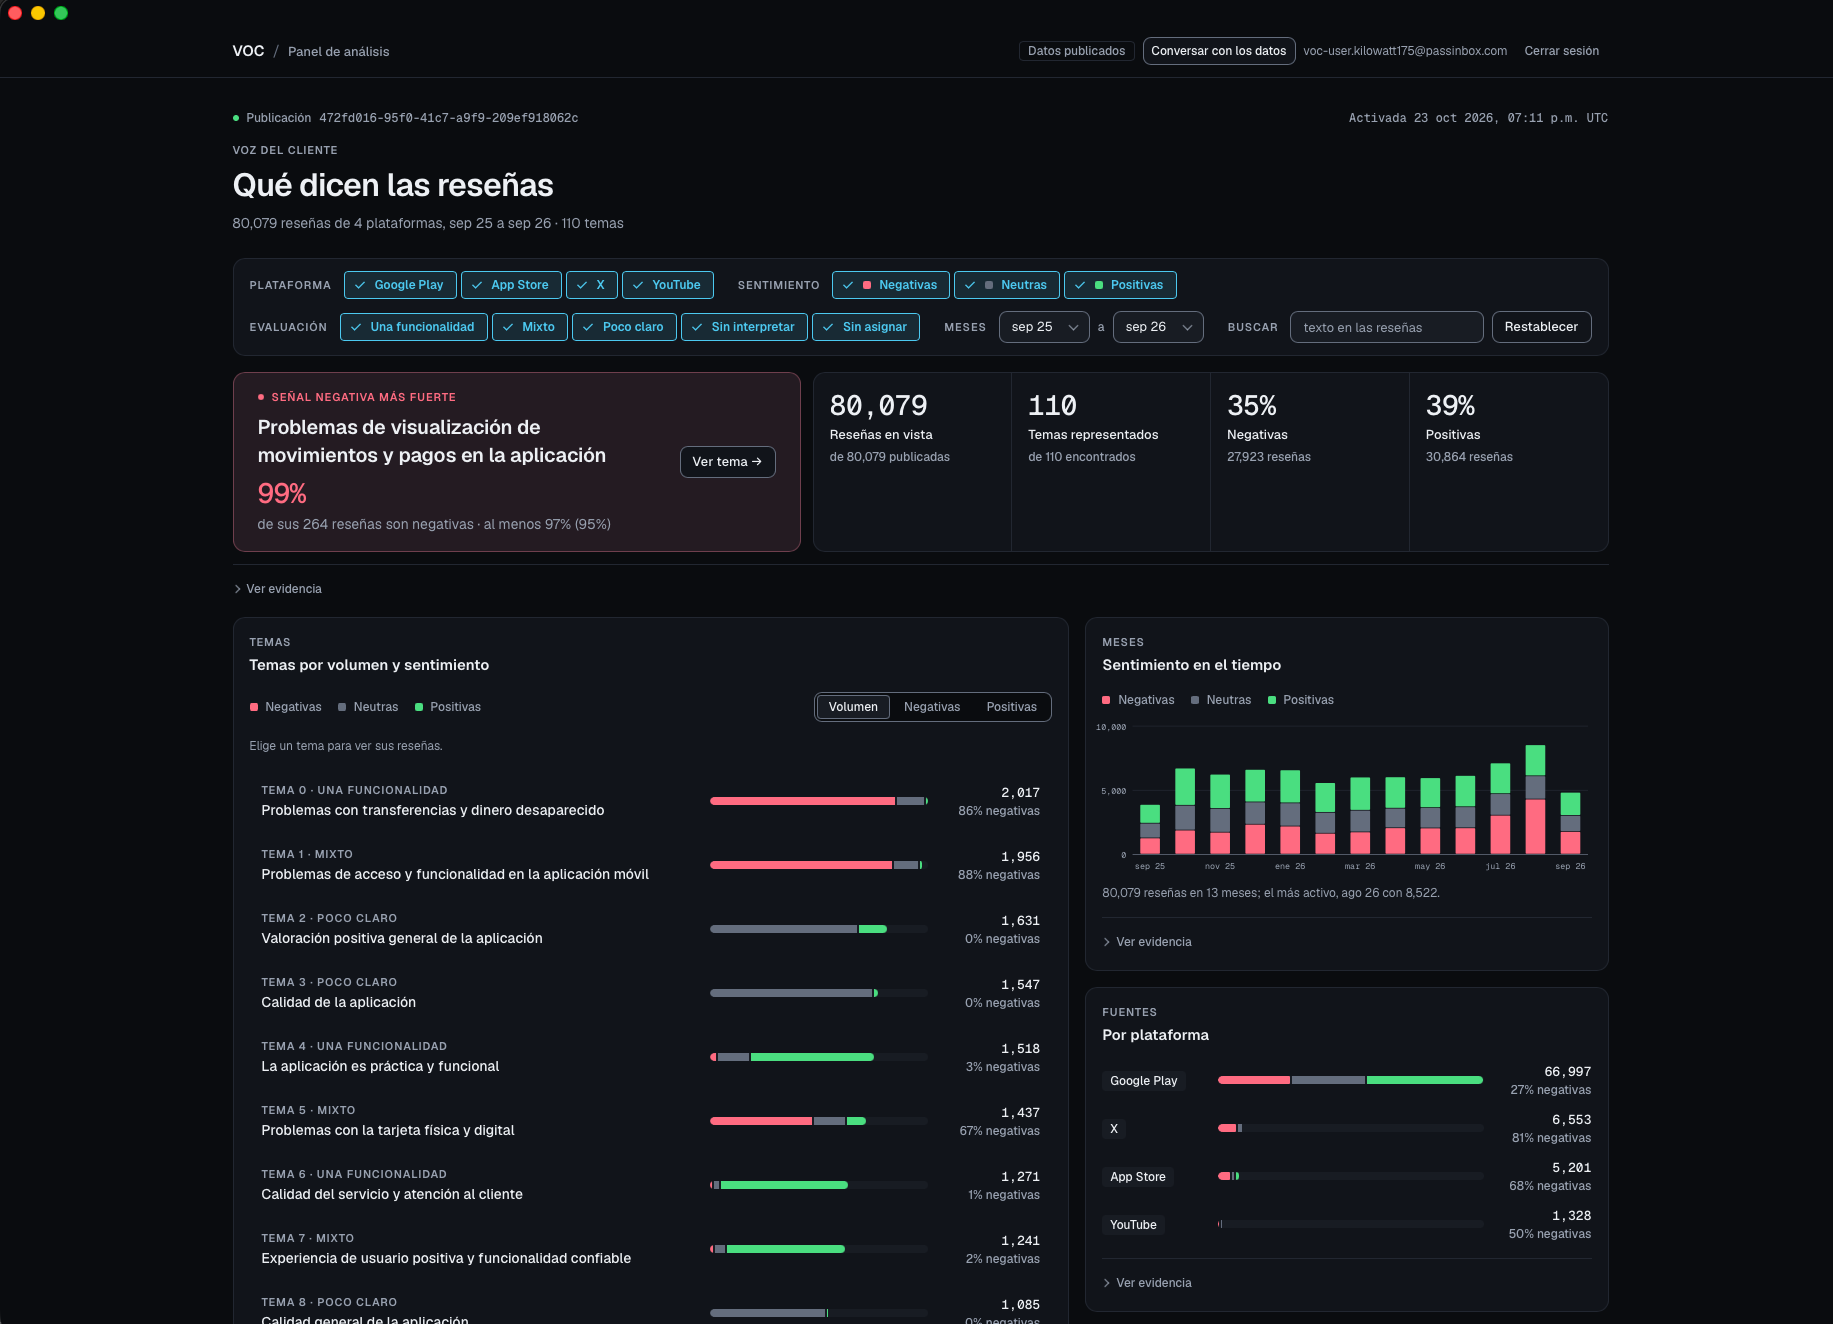

In [14]:
costs=read('costos-openrouter.csv')
costs['family']=costs.model_permaslug.map(lambda x:'Gemini' if 'gemini-2.5-flash' in x else 'Claude')
summary=[]
for family,g in costs.groupby('family'):
    values=[Decimal(str(v)) for v in g.cost_total]
    summary.append(dict(model=family,calls=len(g),total_usd=sum(values),mean_usd=sum(values)/len(g)))
cost_summary=pd.DataFrame(summary).set_index('model');display(cost_summary)
check('210 llamadas Gemini',cost_summary.loc['Gemini','calls']==210)
check('184 llamadas Claude',cost_summary.loc['Claude','calls']==184)
check('Costo medio Gemini del artículo',round(cost_summary.loc['Gemini','mean_usd'],6)==Decimal('0.000704'))
check('Costo medio Claude del artículo',round(cost_summary.loc['Claude','mean_usd'],6)==Decimal('0.006373'))
scenarios=pd.DataFrame([{'calls_per_question':n,'questions':1000,'calls':1000*n,'estimated_usd':round(cost_summary.loc['Claude','mean_usd']*1000*n,2)} for n in [2,4,6]])
check('Escenarios de costo del artículo',list(scenarios.estimated_usd)==[Decimal('12.75'),Decimal('25.49'),Decimal('38.24')])
display(scenarios);scenarios.to_csv(OUT/'costos-escenarios-recalculados.csv',index=False)
for label in ['tab:operacion','tab:costos','tab:escenarios']:show_table(label)
for label in ['fig:arquitectura-operacion-propuesta','fig:ciclo-react-consulta','fig:anexo-dashboard']:show_figure(label)


## 8. Procedencia, alcance y auditoría

Las fuentes del equipo se reúnen aquí para que el artículo pueda citar esta libreta como punto de entrada. Los enlaces conservan la procedencia del prototipo, la entrega previa y el checkpoint histórico. Los artículos y la documentación externa sobre los algoritmos siguen siendo fuentes teóricas independientes.

El paquete tiene hashes que detectan cambios de archivos, pero los hashes no certifican la corrección semántica de sus resultados. Las comprobaciones verifican consistencia y reproducción numérica. No convierten etiquetas asistidas en anotaciones independientes, no prueban causalidad del filtrado ni garantizan que el LLM identifique una funcionalidad útil.

Las figuras documentales se conservan como archivos estáticos. Las figuras calculadas incluyen su versión del artículo y una reconstrucción desde sus datos. Pueden existir diferencias de estilo de trazado entre ambas, sin cambiar sus valores.


In [15]:
sources=load('fuentes-publicas.json')
display(Markdown('[Código del prototipo]('+sources['software']+') · [Trabajo histórico de sentimiento]('+sources['historical_training']+') · [Evaluación del checkpoint]('+sources['model']['url']+')'))
display(pd.DataFrame([{'archivo':path,**meta} for path,meta in manifest['provenance'].items()]))
check('Once figuras del artículo y anexos indexadas',len(fig_index)==11)
check('Ocho tablas y ejemplos indexados',len(report_tables)==8)
check('Sin nuevo entrenamiento ni proveedor',manifest['models_executed']==0 and manifest['provider_calls']==0)
import importlib.metadata
receipt={'state':'passed','checks':checks,'source_manifest_sha256':digest(INPUT/'manifest.json'),'new_model_fits':0,'new_llm_requests':0,
 'scope':'Recomputación de resultados guardados y comprobación de coherencia. No entrenamiento ni evaluación semántica independiente.',
 'software':{name:importlib.metadata.version(name) for name in ['numpy','pandas','matplotlib','scikit-learn']},
 'files':{p.name:digest(p) for p in OUT.iterdir() if p.is_file()}}
(OUT/'verificacion.json').write_text(json.dumps(receipt,ensure_ascii=False,indent=2)+'\n')
(OUT.parent/'latest.json').write_text(json.dumps({'directory':str(OUT.relative_to(ROOT)),'verification_sha256':digest(OUT/'verificacion.json')},indent=2)+'\n')
print(f"Verificación completada: {len(checks)} comprobaciones. Salidas: {OUT.relative_to(ROOT)}")


[Código del prototipo](https://github.com/nessBautista/voc/tree/voc-difusion) · [Trabajo histórico de sentimiento](https://github.com/nessBautista/voc/tree/main/reports/Analisis%20de%20sentimiento) · [Evaluación del checkpoint](https://huggingface.co/Banamex-voc-sentiment/voc-robertuito-sentiment-stores-es/blob/ff48c25f016499fc40d910f2a2a50072c706cdee/evaluation.json)

,archivo,origin,source_sha256,kind,transformation
0,corpus-fechas.csv.gz,data/inputs/corpus/dataset.parquet,a8db7989ea44de41f1f37d1cda8a228dbcc698a505c5ab...,extracto derivado,"Solo identificador, plataforma y fecha. Sin te..."
1,corpus-registros-por-mes-y-fuente.csv,reports/difusion/exports/cobertura-del-corpus/...,1729feff3b04be2da68fb26548f5ce57a6b92d11585f54...,resultado guardado,NaN
2,corpus-procedencia.json,reports/difusion/exports/cobertura-del-corpus/...,882abc110cac0afa15e0ad65a67122ef8bfe490eca55bf...,resultado guardado,NaN
3,relevancia-recibo.json,docs/evidence/relevance-comparison-v1.json,84afad108885057ecddac306f3361ce0780279df768f56...,resultado guardado,NaN
4,relevancia-svm.csv,data/relevance/model-v1/validation.csv,caa7e88ae5c2a2075e80b60914a53a5b1b71f2ca1dea85...,extracto derivado,"Solo IDs, particiones, referencia y prediccion..."
5,relevancia-logreg.csv,data/relevance/model-logreg-v1/validation.csv,06de4773289ec7d3faf78d75b7f9ccdc248b2444d1590a...,extracto derivado,"Solo IDs, particiones, referencia y prediccion..."
6,robertuito-tiendas-v3-evaluation.json,reports/difusion/sources/robertuito-tiendas-v3...,f4d53c2e5552903f5e0315f2efb12756328995ab150e28...,"evaluación histórica, no nuevo entrenamiento",NaN
7,robertuito-provenance.json,reports/difusion/sources/provenance.json,9c88936205f1a1365d7d67bb943e7c7d903e9e5867be6f...,"evaluación histórica, no nuevo entrenamiento",NaN
8,base-asignaciones.csv,reports/difusion/exports/pipeline-base-alterna...,8cb20de91e38e0adef31b3039a19d688beac7d2b636541...,resultado guardado,NaN
9,alternative-asignaciones.csv,reports/difusion/exports/pipeline-base-alterna...,e4eaf6c9dbffac98ba393215461e30455bd4e534874022...,resultado guardado,NaN


Verificación completada: 234 comprobaciones. Salidas: exports/evidencia-articulo-14/20261108T201322755446Z
